# NN Convergence and Capacity Investigation

This local-only audit separates raw displacement convergence from shared geometric support, quantifies direct field differences, parses the GPU-0 training history, and profiles d20/f4096 checkpoint weights.

The primary convergence quantity is the raw three-component nodal displacement, `u_nodes`, trilinearly embedded to the QuESo $512^3$ grid. It is never a stiffness, force, volume fraction, mask, normalized displacement, or precomputed error field.

In [1]:
from __future__ import annotations

import re
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "clean_simulation").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "clean_simulation").is_dir():
    raise RuntimeError("Open this notebook from the repository root or a descendant directory.")

ANALYSIS_DIR = ROOT / "clean_simulation" / "outputs" / "analysis" / "d20_f4096_investigation"
SELECTED_DIR = ROOT / "clean_simulation" / "outputs" / "sphere_displacement_convergence_d20_crystals30_lr1e-6" / "planar_cap_plane_hard_constraints"
CANONICAL_DIR = ROOT / "clean_simulation" / "outputs" / "sphere_displacement_convergence" / "planar_cap_plane_hard_constraints"
RESULTS_PATH = SELECTED_DIR / "three_framework_plane_cap_queso_512_full_reference_support.csv"
LOG_PATH = ANALYSIS_DIR / "d20_f4096_crystals30_from_best_historical_lr2e-6_1h_gpu0.log"
BEST_CHECKPOINT = ROOT / "clean_simulation" / "outputs" / "checkpoints" / "source_sdf_rebuilt_queso_d20_f4096_aws_18h_ddp_historical_batch02_b2880.pt"
LOCAL_DATA = ROOT / "training_filtered.h5"

print(f"Workspace: {ROOT}")
print(f"Corrected selected-study CSV: {RESULTS_PATH.exists()}")
print(f"Local training log: {LOG_PATH.exists()}")
print(f"Best d20/f4096 checkpoint local: {BEST_CHECKPOINT.exists()}")

Workspace: C:\Users\z0058p1u\Documents\code
Corrected selected-study CSV: True
Local training log: True
Best d20/f4096 checkpoint local: False


,framework,framework_label,resolution,reference_resolution,reference_nodes,nodewise_reference_floor_fraction,nodewise_relative_reference_nodes,candidate_nodes_on_reference_support,support_coverage,aligned_node_max_abs_error,embedded_relative_l2_error,embedded_rms_nodewise_relative_error,zero_filled_full_reference_relative_l2_error
0,naive,Naive full-cell Gauss,8,512,40668967,0.0001,40592610,21267585,0.522944,0.0,0.237075,0.248568,0.699221
1,naive,Naive full-cell Gauss,16,512,40668967,0.0001,40592610,28656769,0.704635,0.0,0.216682,0.280553,0.569313
2,naive,Naive full-cell Gauss,32,512,40668967,0.0001,40592610,34234593,0.841787,0.0,0.155558,0.198570,0.413869
3,naive,Naive full-cell Gauss,64,512,40668967,0.0001,40592610,37765345,0.928603,0.0,0.090409,0.109608,0.273167
4,naive,Naive full-cell Gauss,128,512,40668967,0.0001,40592610,39387193,0.968483,0.0,0.062248,0.069597,0.179993
5,naive,Naive full-cell Gauss,256,512,40668967,0.0001,40592610,40234505,0.989317,0.0,0.041782,0.042895,0.104321
6,naive,Naive full-cell Gauss,512,512,40668967,0.0001,40592610,40668967,1.000000,0.0,0.000457,0.000446,0.000457
7,nn,NN-cut-cell hybrid,8,512,40668967,0.0001,40592610,21267585,0.522944,0.0,0.188311,0.211788,0.698771
8,nn,NN-cut-cell hybrid,16,512,40668967,0.0001,40592610,28656769,0.704635,0.0,0.222561,0.285048,0.571881
9,nn,NN-cut-cell hybrid,32,512,40668967,0.0001,40592610,34234593,0.841787,0.0,0.159106,0.201304,0.415487


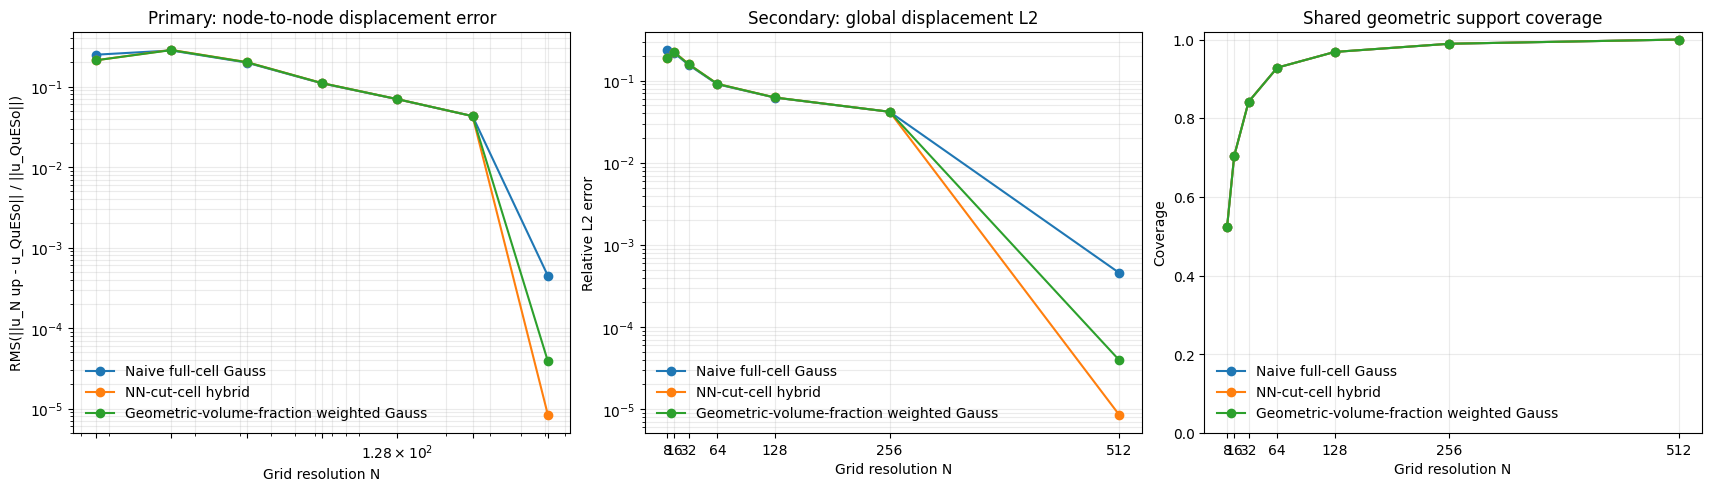

,weighted_minus_nn_percentage_points,naive_minus_nn_percentage_points,weighted_to_nn_nodewise_error_ratio
resolution,,,
8,0.001596,3.677968,1.000075
16,-0.153596,-0.449515,0.994612
32,-0.047538,-0.273477,0.997638
64,-0.009520,-0.086397,0.999138
128,-0.002047,-0.021130,0.999707
256,-0.000632,-0.005677,0.999853
512,0.003036,0.043743,4.630950


In [12]:
if not RESULTS_PATH.is_file():
    raise FileNotFoundError(f"Missing corrected CSV: {RESULTS_PATH}")

results = pd.read_csv(RESULTS_PATH).sort_values(["framework", "resolution"])
display(results)

figure, axes = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)
for framework, curve in results.groupby("framework", sort=False):
    label = curve["framework_label"].iloc[0]
    axes[0].loglog(curve["resolution"], curve["embedded_rms_nodewise_relative_error"], marker="o", label=label)
    axes[1].semilogy(curve["resolution"], curve["embedded_relative_l2_error"], marker="o", label=label)
    axes[2].plot(curve["resolution"], curve["support_coverage"], marker="o", label=label)
axes[0].set(title="Primary: node-to-node displacement error", xlabel="Grid resolution N", ylabel="RMS(||u_N up - u_QuESo|| / ||u_QuESo||)")
axes[1].set(title="Secondary: global displacement L2", xlabel="Grid resolution N", ylabel="Relative L2 error")
axes[2].set(title="Shared geometric support coverage", xlabel="Grid resolution N", ylabel="Coverage", ylim=(0, 1.02))
for axis in axes:
    axis.set_xticks(sorted(results["resolution"].unique()))
    axis.grid(True, which="both", alpha=0.25)
    axis.legend(frameon=False)
plt.show()

nodewise = results.pivot(index="resolution", columns="framework", values="embedded_rms_nodewise_relative_error")
nodewise_gap = pd.DataFrame({
    "weighted_minus_nn_percentage_points": 100 * (nodewise["weighted"] - nodewise["nn"]),
    "naive_minus_nn_percentage_points": 100 * (nodewise["naive"] - nodewise["nn"]),
    "weighted_to_nn_nodewise_error_ratio": nodewise["weighted"] / nodewise["nn"],
})
display(nodewise_gap)

In [13]:
# Consecutive refinement orders for the primary node-to-node metric.
# The 512^3 QuESo field is a discrete reference, so the final 256 -> 512
# pair is reference-contaminated and must not be used to infer a FEM order.
nodewise_curves = results.pivot(index="resolution", columns="framework", values="embedded_rms_nodewise_relative_error").sort_index()
order_rows = []
for framework in nodewise_curves:
    errors = nodewise_curves[framework]
    for coarse_resolution, fine_resolution in zip(errors.index[:-1], errors.index[1:]):
        order_rows.append({
            "framework": framework,
            "coarse_resolution": coarse_resolution,
            "fine_resolution": fine_resolution,
            "coarse_error": errors[coarse_resolution],
            "fine_error": errors[fine_resolution],
            "observed_order": np.log(errors[coarse_resolution] / errors[fine_resolution]) / np.log(fine_resolution / coarse_resolution),
            "reference_contaminated": fine_resolution == 512,
        })
nodewise_orders = pd.DataFrame(order_rows)
display(nodewise_orders)

usable_orders = nodewise_orders.query("not reference_contaminated and coarse_resolution >= 32")
summary = usable_orders.groupby("framework", as_index=False).agg(
    mean_order=("observed_order", "mean"),
    min_order=("observed_order", "min"),
    max_order=("observed_order", "max"),
)
display(summary)

print("Interpretation:")
print("- A P1 FEM L2 order near 2 requires a fixed smooth domain/problem and a reference accurate enough to be treated as continuous.")
print("- This study changes voxelized cut geometry, active support, and constrained-node sets with N; it therefore measures combined geometry, boundary, quadrature/operator, and interpolation error.")
print("- The 256 -> 512 order compares to the discrete QuESo-512 field and is not an asymptotic FEM-order observation.")
print("- To test target method orders (1.2, 1.5, 2), solve one fixed smooth manufactured problem or use identical high-order geometry/BC across N, then evaluate a norm integrated over a fixed physical domain.")

,framework,coarse_resolution,fine_resolution,coarse_error,fine_error,observed_order,reference_contaminated
0,naive,8,16,0.248568,0.280553,-0.174634,False
1,naive,16,32,0.280553,0.198570,0.498631,False
2,naive,32,64,0.198570,0.109608,0.857297,False
3,naive,64,128,0.109608,0.069597,0.655242,False
4,naive,128,256,0.069597,0.042895,0.698220,False
5,naive,256,512,0.042895,0.000446,6.588300,True
6,nn,8,16,0.211788,0.285048,-0.428584,False
7,nn,16,32,0.285048,0.201304,0.501829,False
8,nn,32,64,0.201304,0.110472,0.865704,False
9,nn,64,128,0.110472,0.069809,0.662196,False


,framework,mean_order,min_order,max_order
0,naive,0.736920,0.655242,0.857297
1,nn,0.742862,0.662196,0.865704
2,weighted,0.741796,0.661376,0.863536


Interpretation:
- A P1 FEM L2 order near 2 requires a fixed smooth domain/problem and a reference accurate enough to be treated as continuous.
- This study changes voxelized cut geometry, active support, and constrained-node sets with N; it therefore measures combined geometry, boundary, quadrature/operator, and interpolation error.
- The 256 -> 512 order compares to the discrete QuESo-512 field and is not an asymptotic FEM-order observation.
- To test target method orders (1.2, 1.5, 2), solve one fixed smooth manufactured problem or use identical high-order geometry/BC across N, then evaluate a norm integrated over a fixed physical domain.


Skipping 512^3; missing local archive(s): ['naive', 'weighted', 'nn', 'queso']


,resolution,framework,nodes_compared,rms_nodewise_relative_error,median_nodewise_relative_error,p90_nodewise_relative_error,p99_nodewise_relative_error
0,8,naive,416,0.535353,0.497317,0.663300,1.009148
1,8,weighted,416,1114.698070,2.392174,3.084563,6771.207669
2,8,nn,416,1.883577,1.000000,2.878898,4.560847
3,16,naive,2098,0.417035,0.378560,0.514614,0.792878
4,16,weighted,2098,1210.212231,1.387678,1.826960,6927.317638
5,16,nn,2098,1.443413,1.174826,1.683034,4.527673
6,32,naive,13180,0.318417,0.242945,0.327087,0.722396
7,32,weighted,13180,10.115519,0.617583,0.869386,5.268200
8,32,nn,13180,0.864309,0.662776,1.000000,2.064761
9,64,naive,92034,0.167864,0.131910,0.177224,0.380887


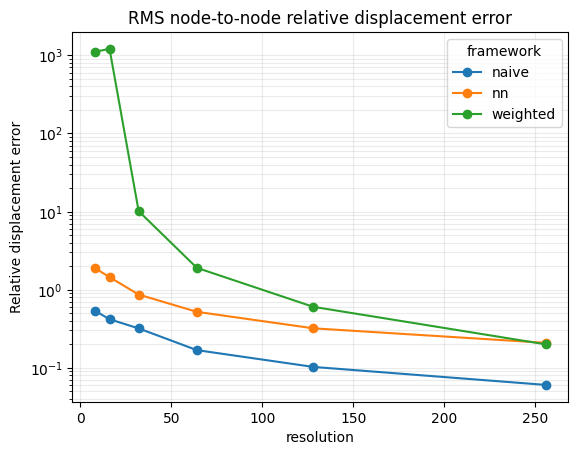

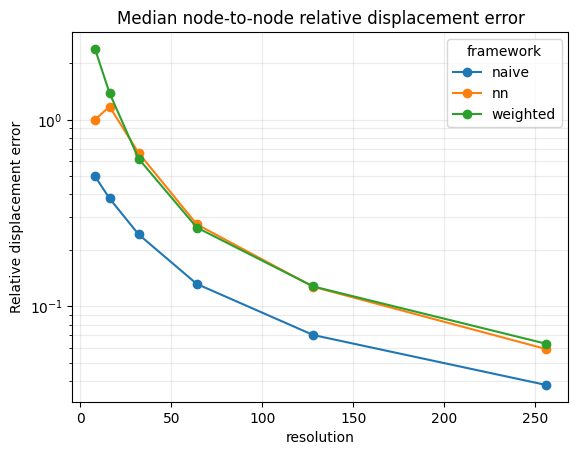

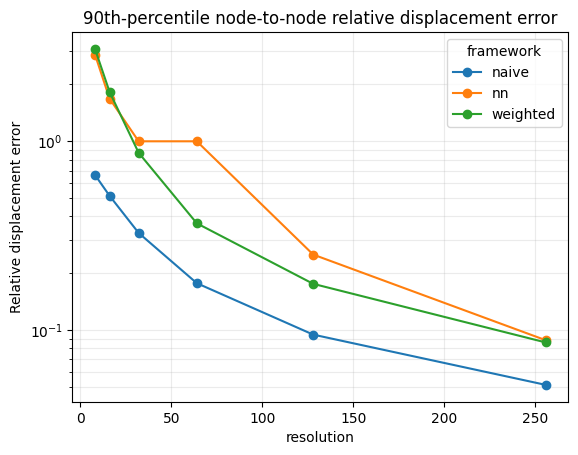

In [10]:
# Same-grid node-to-node displacement error distribution. This is an
# independent local check that does not aggregate vector errors globally.
def archive_path(framework: str, resolution: int) -> Path:
    selected = SELECTED_DIR / f"hanging_sphere_{framework}_displacement_{resolution}cubed.npz"
    canonical = CANONICAL_DIR / f"hanging_sphere_{framework}_displacement_{resolution}cubed.npz"
    # NN must always be the selected d20/f4096 study. Returning its expected
    # path lets the loop skip a not-yet-downloaded resolution without mixing studies.
    return selected if framework == "nn" else selected if selected.is_file() else canonical

rows = []
for resolution in (8, 16, 32, 64, 128, 256, 512):
    paths = {name: archive_path(name, resolution) for name in ("naive", "weighted", "nn", "queso")}
    if not all(path.is_file() for path in paths.values()):
        print(f"Skipping {resolution}^3; missing local archive(s): {[name for name, path in paths.items() if not path.is_file()]}")
        continue
    archives = {name: np.load(path, allow_pickle=True) for name, path in paths.items()}
    reference = archives["queso"]["u_nodes"].astype(np.float64)
    reference_nodes = node_mask_from_active_cells(archives["queso"]["active_cells"], resolution)
    reference_magnitude = np.linalg.norm(reference, axis=1)
    floor = max(float(reference_magnitude[reference_nodes].max()) * 1e-12, np.finfo(float).tiny)
    valid_nodes = reference_nodes & (reference_magnitude > floor)
    for framework in ("naive", "weighted", "nn"):
        candidate = archives[framework]["u_nodes"].astype(np.float64)
        node_error = np.linalg.norm(candidate[valid_nodes] - reference[valid_nodes], axis=1) / reference_magnitude[valid_nodes]
        rows.append({
            "resolution": resolution,
            "framework": framework,
            "nodes_compared": int(valid_nodes.sum()),
            "rms_nodewise_relative_error": np.sqrt(np.mean(node_error ** 2)),
            "median_nodewise_relative_error": np.median(node_error),
            "p90_nodewise_relative_error": np.quantile(node_error, 0.90),
            "p99_nodewise_relative_error": np.quantile(node_error, 0.99),
        })
nodewise_same_grid = pd.DataFrame(rows)
display(nodewise_same_grid)

for metric, title in (("rms_nodewise_relative_error", "RMS node-to-node relative displacement error"),
                      ("median_nodewise_relative_error", "Median node-to-node relative displacement error"),
                      ("p90_nodewise_relative_error", "90th-percentile node-to-node relative displacement error")):
    pivot = nodewise_same_grid.pivot(index="resolution", columns="framework", values=metric)
    pivot.plot(marker="o", logy=True, title=title)
    plt.ylabel("Relative displacement error")
    plt.grid(True, which="both", alpha=0.25)
    plt.show()

,resolution,framework,reference_floor_fraction,nodes_compared,rms_nodewise_relative_error,median_nodewise_relative_error
0,8,naive,1.000000e-12,416,0.535353,0.497317
1,8,weighted,1.000000e-12,416,1114.698070,2.392174
2,8,nn,1.000000e-12,416,1.883577,1.000000
3,8,naive,1.000000e-08,416,0.535353,0.497317
4,8,weighted,1.000000e-08,416,1114.698070,2.392174
...,...,...,...,...,...,...
85,256,weighted,1.000000e-04,5263626,0.084447,0.063165
86,256,nn,1.000000e-04,5263626,0.205665,0.059156
87,256,naive,1.000000e-03,5230463,0.045664,0.038027
88,256,weighted,1.000000e-03,5230463,0.084467,0.063211


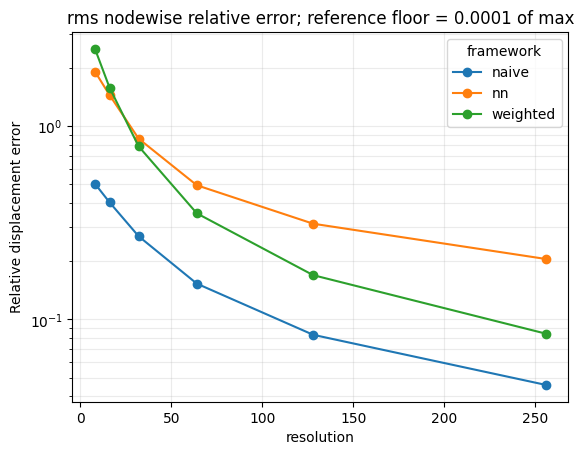

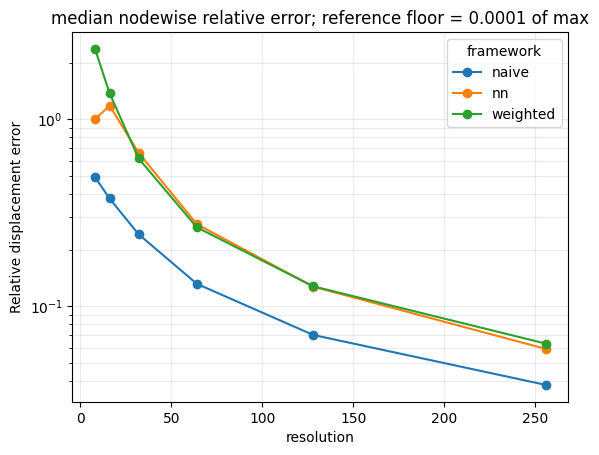

In [11]:
# Relative errors are undefined in the limit ||u_QuESo|| -> 0. Audit the
# denominator threshold explicitly instead of allowing a few near-zero nodes
# to dominate an RMS statistic.
FLOOR_FRACTIONS = (1e-12, 1e-8, 1e-6, 1e-4, 1e-3)
sensitivity_rows = []
for resolution in (8, 16, 32, 64, 128, 256):
    paths = {name: archive_path(name, resolution) for name in ("naive", "weighted", "nn", "queso")}
    if not all(path.is_file() for path in paths.values()):
        continue
    archives = {name: np.load(path, allow_pickle=True) for name, path in paths.items()}
    reference = archives["queso"]["u_nodes"].astype(np.float64)
    reference_nodes = node_mask_from_active_cells(archives["queso"]["active_cells"], resolution)
    reference_magnitude = np.linalg.norm(reference, axis=1)
    maximum = reference_magnitude[reference_nodes].max()
    for floor_fraction in FLOOR_FRACTIONS:
        valid_nodes = reference_nodes & (reference_magnitude > maximum * floor_fraction)
        for framework in ("naive", "weighted", "nn"):
            candidate = archives[framework]["u_nodes"].astype(np.float64)
            node_error = np.linalg.norm(candidate[valid_nodes] - reference[valid_nodes], axis=1) / reference_magnitude[valid_nodes]
            sensitivity_rows.append({
                "resolution": resolution,
                "framework": framework,
                "reference_floor_fraction": floor_fraction,
                "nodes_compared": int(valid_nodes.sum()),
                "rms_nodewise_relative_error": np.sqrt(np.mean(node_error ** 2)),
                "median_nodewise_relative_error": np.median(node_error),
            })
nodewise_floor_sensitivity = pd.DataFrame(sensitivity_rows)
display(nodewise_floor_sensitivity)

# 1e-4 removes only numerical/near-fixed reference nodes while preserving the
# physical displacement field. Use this explicitly labelled threshold for the
# RMS comparison below.
ROBUST_FLOOR_FRACTION = 1e-4
robust_nodewise = nodewise_floor_sensitivity.query("reference_floor_fraction == @ROBUST_FLOOR_FRACTION")
for metric in ("rms_nodewise_relative_error", "median_nodewise_relative_error"):
    robust_nodewise.pivot(index="resolution", columns="framework", values=metric).plot(marker="o", logy=True)
    plt.title(f"{metric.replace('_', ' ')}; reference floor = {ROBUST_FLOOR_FRACTION:g} of max")
    plt.ylabel("Relative displacement error")
    plt.grid(True, which="both", alpha=0.25)
    plt.show()

c:\Users\z0058p1u\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]


,resolution,region,nodes,weighted_minus_nn_l2_over_queso_active_norm,weighted_nn_correlation
0,8,physical three-way overlap,461,2.265466,0.982541
1,8,physical union,461,2.265466,0.982541
2,8,outside physical union,268,0.000000,NaN
3,16,physical three-way overlap,2199,1.347813,0.988584
4,16,physical union,2199,1.347813,0.988584
5,16,outside physical union,2714,0.000000,NaN
6,32,physical three-way overlap,13421,0.621991,0.995102
7,32,physical union,13421,0.621991,0.995102
8,32,outside physical union,22516,0.000000,NaN
9,64,physical three-way overlap,92703,0.269300,0.998570


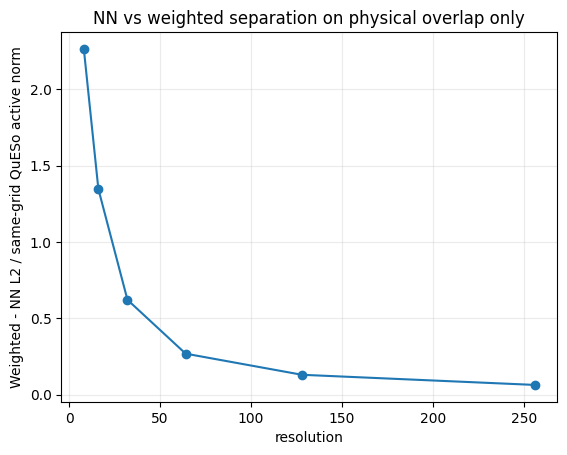

In [6]:
# Decompose the raw same-grid field differences. Values at nodes outside an
# operator's active support are not physical comparison data, so the earlier
# raw-vector separation is intentionally split by mask here.
def node_mask_from_active_cells(active_cells: np.ndarray, resolution: int) -> np.ndarray:
    cells = np.zeros((resolution, resolution, resolution), dtype=bool)
    cells.reshape(-1)[active_cells] = True
    nodes = np.zeros((resolution + 1, resolution + 1, resolution + 1), dtype=bool)
    for ox, oy, oz in ((0, 0, 0), (1, 0, 0), (1, 1, 0), (0, 1, 0),
                       (0, 0, 1), (1, 0, 1), (1, 1, 1), (0, 1, 1)):
        nodes[ox:ox + resolution, oy:oy + resolution, oz:oz + resolution] |= cells
    return nodes.reshape(-1)

mask_rows = []
for resolution in (8, 16, 32, 64, 128, 256):
    paths = {name: archive_path(name, resolution) for name in ("weighted", "nn", "queso")}
    if not all(path.is_file() for path in paths.values()):
        continue
    archives = {name: np.load(path, allow_pickle=True) for name, path in paths.items()}
    fields = {name: archive["u_nodes"].astype(np.float64) for name, archive in archives.items()}
    masks = {name: node_mask_from_active_cells(archive["active_cells"], resolution) for name, archive in archives.items()}
    overlap = masks["weighted"] & masks["nn"] & masks["queso"]
    union = masks["weighted"] | masks["nn"] | masks["queso"]
    difference = fields["weighted"] - fields["nn"]
    queso_norm = np.linalg.norm(fields["queso"][masks["queso"]])
    for region_name, region in (("physical three-way overlap", overlap), ("physical union", union), ("outside physical union", ~union)):
        mask_rows.append({
            "resolution": resolution,
            "region": region_name,
            "nodes": int(region.sum()),
            "weighted_minus_nn_l2_over_queso_active_norm": np.linalg.norm(difference[region]) / max(queso_norm, np.finfo(float).tiny),
            "weighted_nn_correlation": np.corrcoef(fields["weighted"][region].ravel(), fields["nn"][region].ravel())[0, 1] if region.any() else np.nan,
        })
mask_decomposition = pd.DataFrame(mask_rows)
display(mask_decomposition)

physical_gap = mask_decomposition[mask_decomposition["region"] == "physical three-way overlap"]
physical_gap.pivot(index="resolution", columns="region", values="weighted_minus_nn_l2_over_queso_active_norm").plot(marker="o", legend=False)
plt.ylabel("Weighted - NN L2 / same-grid QuESo active norm")
plt.title("NN vs weighted separation on physical overlap only")
plt.grid(True, which="both", alpha=0.25)
plt.show()

,epoch,train_loss,validation_loss,learning_rate,spike_retry
0,1,0.023322,0.019397,0.000002,False
1,2,0.018911,0.018932,0.000002,False
2,3,0.018825,0.019209,0.000002,False
3,4,0.018827,0.018994,0.000002,False
4,5,0.018865,0.019109,0.000002,False
5,6,0.018846,0.019131,0.000002,False
6,7,0.018621,0.018765,0.000002,True
7,8,0.019027,0.019175,0.000002,False
8,9,0.018944,0.019400,0.000002,False
9,10,0.018924,0.019396,0.000002,False


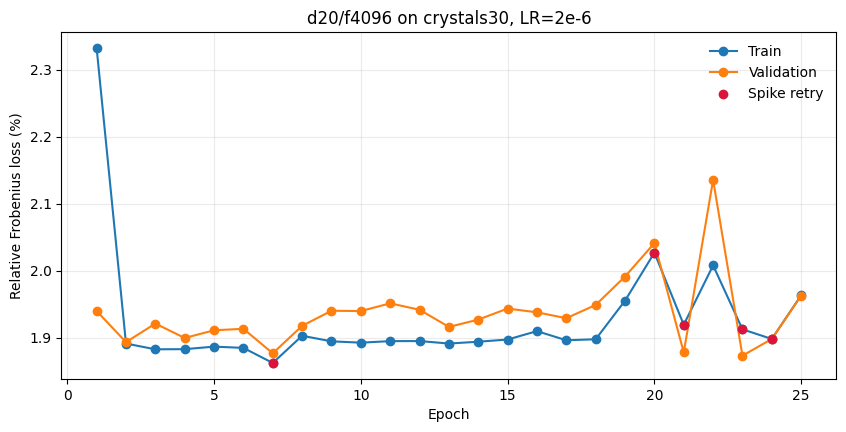

Best logged validation: 1.8730% at epoch 23


In [4]:
if not LOG_PATH.is_file():
    raise FileNotFoundError(f"Missing local log: {LOG_PATH}")

epoch_pattern = re.compile(r"Epoch\s+(\d+)/\d+ \| Train: ([0-9.eE+-]+) \| Val: ([0-9.eE+-]+).*?Lr: ([0-9.eE+-]+)")
spike_pattern = re.compile(r"Epoch\s+(\d+): loss spiked")
epochs, spikes = [], set()
for line in LOG_PATH.read_text(encoding="utf-8", errors="replace").splitlines():
    match = epoch_pattern.search(line)
    if match:
        epoch, train, validation, learning_rate = match.groups()
        epochs.append({"epoch": int(epoch), "train_loss": float(train), "validation_loss": float(validation), "learning_rate": float(learning_rate)})
    match = spike_pattern.search(line)
    if match:
        spikes.add(int(match.group(1)))
history = pd.DataFrame(epochs).drop_duplicates("epoch", keep="last")
history["spike_retry"] = history["epoch"].isin(spikes)
display(history)

figure, axis = plt.subplots(figsize=(10, 4.5))
axis.plot(history["epoch"], 100 * history["train_loss"], marker="o", label="Train")
axis.plot(history["epoch"], 100 * history["validation_loss"], marker="o", label="Validation")
axis.scatter(history.loc[history["spike_retry"], "epoch"], 100 * history.loc[history["spike_retry"], "train_loss"], color="crimson", label="Spike retry", zorder=3)
axis.set(xlabel="Epoch", ylabel="Relative Frobenius loss (%)", title="d20/f4096 on crystals30, LR=2e-6")
axis.grid(True, alpha=0.25)
axis.legend(frameon=False)
plt.show()
print(f"Best logged validation: {100 * history.validation_loss.min():.4f}% at epoch {int(history.loc[history.validation_loss.idxmin(), 'epoch'])}")

,run,checkpoint_epoch,checkpoint_validation_loss,total_float_parameters,rezero_gate_abs_mean,rezero_gate_abs_max,large_matrix_stable_rank_fraction_median,large_matrix_stable_rank_fraction_min
0,historical_best,698,0.016705,672344193,0.010730,0.015318,0.026963,0.016529
1,crystals30_finetune,23,0.018730,672344193,0.010741,0.015338,0.026923,0.016501


,subsystem,parameters
12,trunk.11,33579009
9,trunk.0,33579009
10,trunk.1,33579009
11,trunk.10,33579009
21,trunk.2,33579009
20,trunk.19,33579009
19,trunk.18,33579009
18,trunk.17,33579009
17,trunk.16,33579009
16,trunk.15,33579009


run,name,crystals30_finetune,historical_best,absolute_change
0,trunk.0.alpha,0.012702,0.012682,0.000020
3,trunk.11.alpha,-0.015338,-0.015318,0.000020
15,trunk.5.alpha,0.013458,0.013442,0.000016
19,trunk.9.alpha,0.009625,0.009609,0.000016
13,trunk.3.alpha,0.012729,0.012712,0.000016
8,trunk.16.alpha,0.012496,0.012482,0.000013
14,trunk.4.alpha,0.007788,0.007777,0.000011
4,trunk.12.alpha,-0.010529,-0.010518,0.000011
1,trunk.1.alpha,0.010875,0.010864,0.000011
18,trunk.8.alpha,-0.011077,-0.011068,0.000010


run,name,crystals30_finetune,historical_best,absolute_change
19,trunk.17.fc2.weight,0.050109,0.066425,0.016316
38,trunk.9.fc1.weight,0.049554,0.049686,0.000132
36,trunk.8.fc1.weight,0.037036,0.037165,0.000128
24,trunk.2.fc1.weight,0.036116,0.036227,0.000111
0,trunk.0.fc1.weight,0.044277,0.044377,0.000099
18,trunk.17.fc1.weight,0.033542,0.033611,0.000069
14,trunk.15.fc1.weight,0.032748,0.032814,0.000066
4,trunk.10.fc1.weight,0.038349,0.038415,0.000065
6,trunk.11.fc1.weight,0.023745,0.023802,0.000057
26,trunk.3.fc1.weight,0.024303,0.024360,0.000057


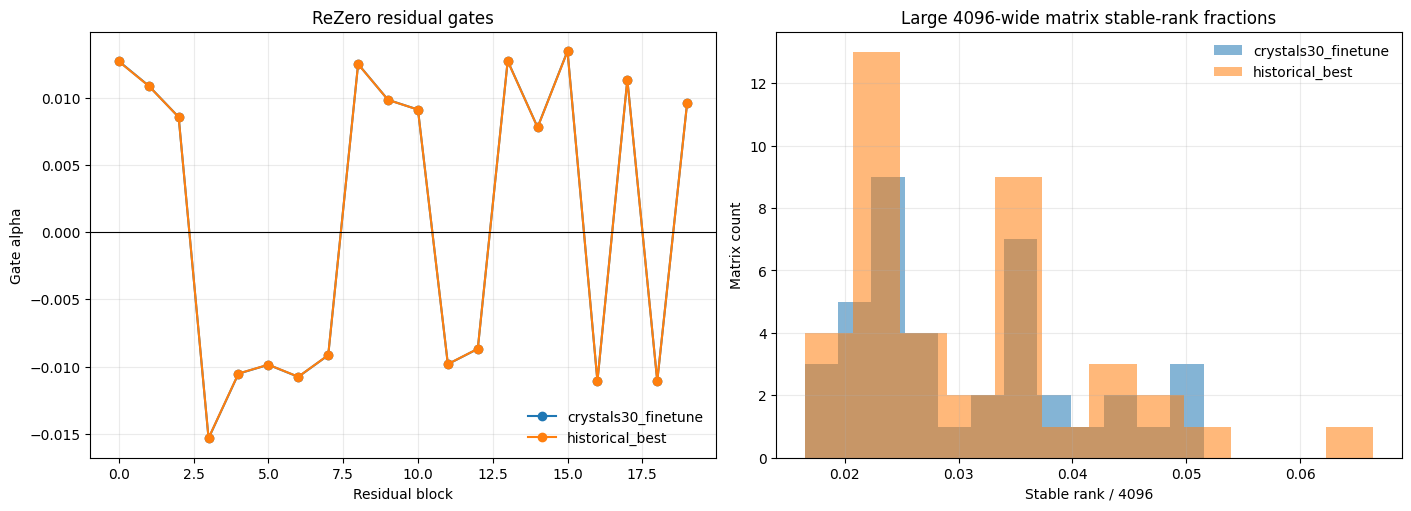

Weight diagnosis:
- 670M of 672M parameters are in the residual trunk; the model is vastly wider than its heads.
- Gates remain near 0.01, so the residual transforms contribute only about one percent of their nominal scale.
- Median stable-rank fraction near 0.027 means a 4096-wide matrix uses roughly 110 effective directions.
- The crystals30 fine-tune left both gate magnitudes and stable ranks essentially unchanged, proving its LR/update regime did not train the deep trunk.


In [14]:
# Weight diagnostics were computed from the full 2.7 GB checkpoints on AWS
# and synchronized as compact reports, so this local notebook remains usable
# without silently substituting a different model.
import json

PROFILE_FILES = {
    "historical_best": {
        "summary": ANALYSIS_DIR / "best_d20_f4096_weight_summary.json",
        "tensors": ANALYSIS_DIR / "best_d20_f4096_weight_tensors.csv",
        "ranks": ANALYSIS_DIR / "best_d20_f4096_large_matrix_ranks.csv",
        "gates": ANALYSIS_DIR / "best_d20_f4096_rezero_gates.csv",
    },
    "crystals30_finetune": {
        "summary": ANALYSIS_DIR / "crystals30_epoch90_d20_f4096_weight_summary.json",
        "ranks": ANALYSIS_DIR / "crystals30_epoch90_d20_f4096_large_matrix_ranks.csv",
        "gates": ANALYSIS_DIR / "crystals30_epoch90_d20_f4096_rezero_gates.csv",
    },
}
missing = [str(path) for files in PROFILE_FILES.values() for path in files.values() if not path.is_file()]
if missing:
    raise FileNotFoundError("Missing synchronized weight reports: " + ", ".join(missing))

weight_summaries = pd.DataFrame([
    {"run": run, **json.loads(files["summary"].read_text(encoding="utf-8"))}
    for run, files in PROFILE_FILES.items()
])
display(weight_summaries[[
    "run", "checkpoint_epoch", "checkpoint_validation_loss", "total_float_parameters",
    "rezero_gate_abs_mean", "rezero_gate_abs_max", "large_matrix_stable_rank_fraction_median",
    "large_matrix_stable_rank_fraction_min",
]])

historical_tensors = pd.read_csv(PROFILE_FILES["historical_best"]["tensors"])
subsystem_parameters = historical_tensors.groupby("subsystem", as_index=False).parameters.sum().sort_values("parameters", ascending=False)
display(subsystem_parameters)

all_gates = pd.concat([
    pd.read_csv(files["gates"]).assign(run=run)
    for run, files in PROFILE_FILES.items()
], ignore_index=True)
gate_comparison = all_gates.pivot(index="name", columns="run", values="mean").reset_index()
gate_comparison["absolute_change"] = (gate_comparison["crystals30_finetune"] - gate_comparison["historical_best"]).abs()
display(gate_comparison.sort_values("absolute_change", ascending=False))

all_ranks = pd.concat([
    pd.read_csv(files["ranks"]).assign(run=run)
    for run, files in PROFILE_FILES.items()
], ignore_index=True)
rank_comparison = all_ranks.pivot(index="name", columns="run", values="stable_rank_fraction").reset_index()
rank_comparison["absolute_change"] = (rank_comparison["crystals30_finetune"] - rank_comparison["historical_best"]).abs()
display(rank_comparison.sort_values("absolute_change", ascending=False))

figure, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for run, values in all_gates.groupby("run"):
    axes[0].plot(range(len(values)), values.sort_values("name")["mean"], marker="o", label=run)
axes[0].axhline(0.0, color="black", linewidth=0.8)
axes[0].set(title="ReZero residual gates", xlabel="Residual block", ylabel="Gate alpha")
axes[0].grid(True, alpha=0.25)
axes[0].legend(frameon=False)
for run, values in all_ranks.groupby("run"):
    axes[1].hist(values["stable_rank_fraction"], bins=12, alpha=0.55, label=run)
axes[1].set(title="Large 4096-wide matrix stable-rank fractions", xlabel="Stable rank / 4096", ylabel="Matrix count")
axes[1].grid(True, alpha=0.25)
axes[1].legend(frameon=False)
plt.show()

print("Weight diagnosis:")
print("- 670M of 672M parameters are in the residual trunk; the model is vastly wider than its heads.")
print("- Gates remain near 0.01, so the residual transforms contribute only about one percent of their nominal scale.")
print("- Median stable-rank fraction near 0.027 means a 4096-wide matrix uses roughly 110 effective directions.")
print("- The crystals30 fine-tune left both gate magnitudes and stable ranks essentially unchanged, proving its LR/update regime did not train the deep trunk.")

,run,block,alpha,branch_to_skip_ratio_mean,branch_to_skip_ratio_median,branch_to_skip_ratio_p90,branch_to_skip_ratio_max
0,historical_best,0,0.012682,0.035426,0.034688,0.045398,0.184908
1,historical_best,1,0.010864,0.036794,0.035664,0.053239,0.143024
2,historical_best,2,-0.008679,0.023235,0.020208,0.035124,0.085103
3,historical_best,3,0.012712,0.027018,0.026647,0.033651,0.126702
4,historical_best,4,0.007777,0.019187,0.018768,0.026026,0.055753
5,historical_best,5,0.013442,0.034627,0.032823,0.046985,0.193129
6,historical_best,6,-0.011073,0.025420,0.024292,0.036161,0.079956
7,historical_best,7,0.011326,0.033305,0.034780,0.044396,0.136396
8,historical_best,8,-0.011068,0.031537,0.031017,0.038246,0.128988
9,historical_best,9,0.009609,0.019238,0.019062,0.025685,0.054837


,run,mean_branch_to_skip,median_branch_to_skip,p90_branch_to_skip,maximum_branch_to_skip
0,crystals30_finetune,0.028713,0.028085,0.039372,0.193387
1,historical_best,0.028676,0.028050,0.039332,0.193129


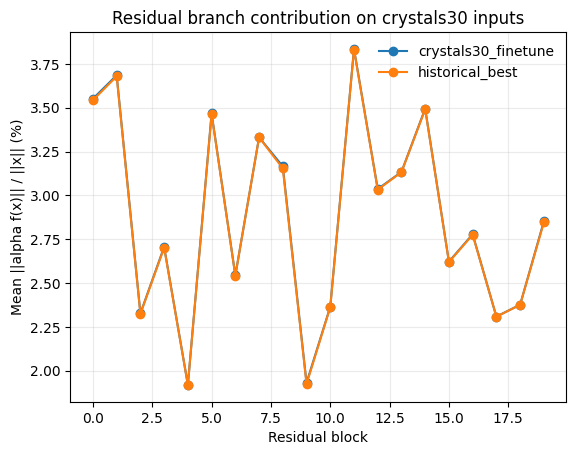

Measured result: the deep residual branch contributes about 2.87% of the skip-path norm on average.
The failed fine-tune changed this quantity negligibly, so the current low-LR, large-batch regime does not materially train the trunk.
Input contract: eight signed-distance values only; Poisson ratio and class conditioning are disabled.


In [16]:
# Direct inference-time test of the ReZero path: for each residual block,
# measure ||alpha * f(x)|| / ||x|| on 8,192 representative crystals30 rows.
ACTIVATION_REPORT = ANALYSIS_DIR / "d20_f4096_residual_activation_ratios.csv"
if not ACTIVATION_REPORT.is_file():
    raise FileNotFoundError(f"Missing activation report: {ACTIVATION_REPORT}")

activation_ratios = pd.read_csv(ACTIVATION_REPORT)
display(activation_ratios)
display(activation_ratios.groupby("run", as_index=False).agg(
    mean_branch_to_skip=("branch_to_skip_ratio_mean", "mean"),
    median_branch_to_skip=("branch_to_skip_ratio_median", "mean"),
    p90_branch_to_skip=("branch_to_skip_ratio_p90", "mean"),
    maximum_branch_to_skip=("branch_to_skip_ratio_max", "max"),
))

for run, values in activation_ratios.groupby("run"):
    plt.plot(values["block"], 100 * values["branch_to_skip_ratio_mean"], marker="o", label=run)
plt.title("Residual branch contribution on crystals30 inputs")
plt.xlabel("Residual block")
plt.ylabel("Mean ||alpha f(x)|| / ||x|| (%)")
plt.grid(True, alpha=0.25)
plt.legend(frameon=False)
plt.show()

print("Measured result: the deep residual branch contributes about 2.87% of the skip-path norm on average.")
print("The failed fine-tune changed this quantity negligibly, so the current low-LR, large-batch regime does not materially train the trunk.")
print("Input contract: eight signed-distance values only; Poisson ratio and class conditioning are disabled.")

In [5]:
if LOCAL_DATA.is_file():
    with h5py.File(LOCAL_DATA, "r") as handle:
        print("Local HDF5 datasets:")
        def show_dataset(name, obj):
            if isinstance(obj, h5py.Dataset):
                print(f"{name}: shape={obj.shape}, dtype={obj.dtype}")
        handle.visititems(show_dataset)
else:
    print(f"Local dataset not found: {LOCAL_DATA}")

print("Capacity decision rule:")
print("- Train loss much lower than validation loss: overfitting; reduce capacity or regularize.")
print("- Both losses plateau together: optimization, target noise, feature representation, or insufficient effective capacity.")
print("- Healthy weights with both losses high do not support a 'too big' conclusion by themselves.")

Local HDF5 datasets:
integration_2_poly_1/cut_volume_fraction: shape=(536339,), dtype=float64
integration_2_poly_1/d_values: shape=(536339, 8), dtype=float64
integration_2_poly_1/flat_index: shape=(536339,), dtype=int64
integration_2_poly_1/geometry_name: shape=(536339,), dtype=|S64
integration_2_poly_1/stiffness_ut: shape=(536339, 300), dtype=float64
Capacity decision rule:
- Train loss much lower than validation loss: overfitting; reduce capacity or regularize.
- Both losses plateau together: optimization, target noise, feature representation, or insufficient effective capacity.
- Healthy weights with both losses high do not support a 'too big' conclusion by themselves.


,p50,p90,p95,p99,p99.9
model,,,,,
resnet_stage1_on_material_parity,2.3559%,17.9661%,26.7679%,47.2136%,95.2806%
transformer_stage1_on_material_parity,3.1123%,16.5223%,25.5990%,49.6072%,125.8037%


,model,volume_bin,samples,mean_loss,median_loss,p95_loss,loss_mass,loss_mass_share
4,resnet_stage1_on_material_parity,"(0.15, 0.5]",25878,6.1850%,4.1013%,18.1171%,1600.562073,21.30%
1,resnet_stage1_on_material_parity,"(0.005, 0.02]",7050,22.2353%,18.8155%,53.2229%,1567.590136,20.87%
3,resnet_stage1_on_material_parity,"(0.05, 0.15]",12330,11.0457%,7.7729%,30.7374%,1361.938931,18.13%
2,resnet_stage1_on_material_parity,"(0.02, 0.05]",7126,17.1549%,13.9900%,43.7071%,1222.460568,16.27%
5,resnet_stage1_on_material_parity,"(0.5, 0.85]",24754,3.3599%,2.2877%,10.2421%,831.721311,11.07%
0,resnet_stage1_on_material_parity,"(-0.001, 0.005]",4360,13.4231%,8.5039%,31.8163%,585.248236,7.79%
6,resnet_stage1_on_material_parity,"(0.85, 0.98]",17706,1.5543%,1.0453%,4.7016%,275.196115,3.66%
7,resnet_stage1_on_material_parity,"(0.98, 1.0]",16140,0.4218%,0.2141%,1.2490%,68.084721,0.91%
12,transformer_stage1_on_material_parity,"(0.15, 0.5]",25960,6.5929%,4.5521%,17.3638%,1711.521246,21.59%
9,transformer_stage1_on_material_parity,"(0.005, 0.02]",6938,22.6558%,15.9151%,55.6220%,1571.862640,19.82%


,model,geometry_name,samples,mean_loss,p95_loss,loss_mass,loss_mass_share
31,resnet_stage1_on_material_parity,eggcarton_sphere,6699,14.9597%,47.9746%,1002.148180,13.34%
20,resnet_stage1_on_material_parity,crystal_0019,3396,14.2040%,61.6116%,482.368760,6.42%
35,resnet_stage1_on_material_parity,star_lobe_sphere,4857,5.2444%,25.0659%,254.718260,3.39%
3,resnet_stage1_on_material_parity,crystal_0002,3669,6.0754%,24.3888%,222.906929,2.97%
16,resnet_stage1_on_material_parity,crystal_0015,3519,6.2904%,24.5069%,221.360700,2.95%
26,resnet_stage1_on_material_parity,crystal_0025,3500,6.0284%,24.5438%,210.992587,2.81%
9,resnet_stage1_on_material_parity,crystal_0008,3236,6.4930%,26.8922%,210.114072,2.80%
4,resnet_stage1_on_material_parity,crystal_0003,3043,6.7091%,27.3730%,204.156698,2.72%
18,resnet_stage1_on_material_parity,crystal_0017,3194,6.3632%,26.1777%,203.241985,2.71%
17,resnet_stage1_on_material_parity,crystal_0016,3322,6.0956%,24.6754%,202.497372,2.70%


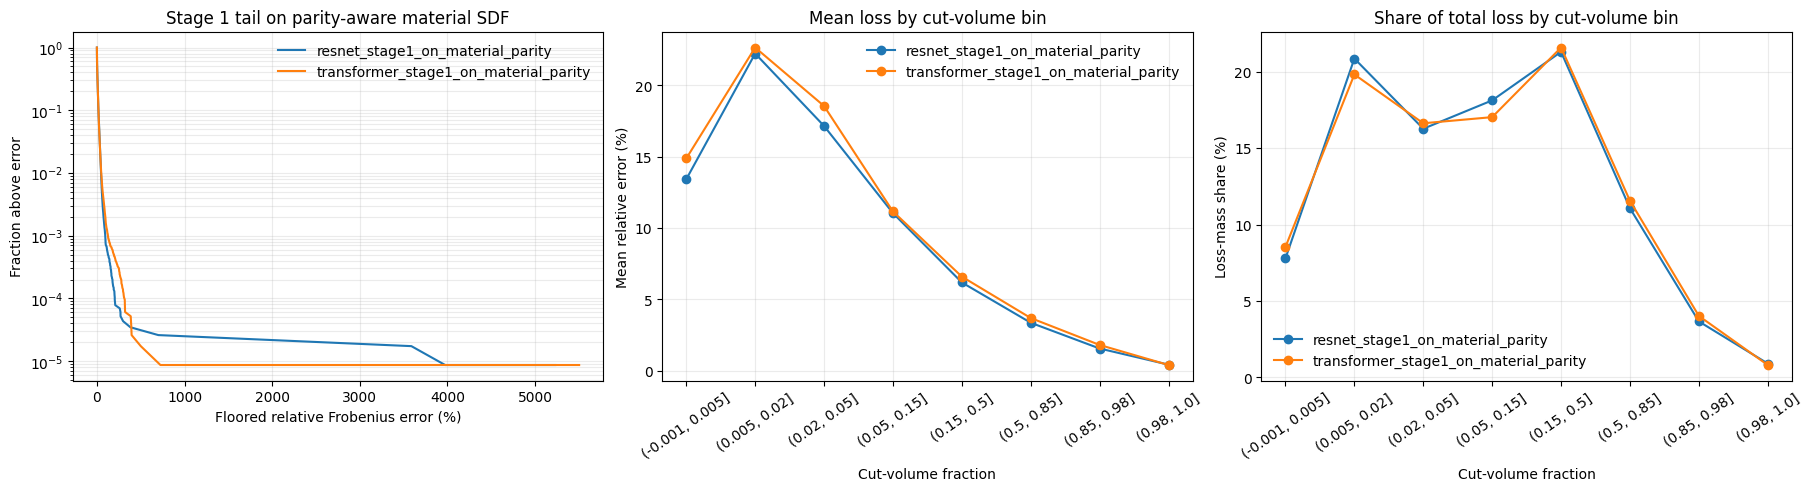

The displayed loss uses the same 5th-percentile target-norm floor as training.
These are protected Stage 1 checkpoints evaluated on the corrected representation, not retrained material-parity models.


In [21]:
# Held-out loss distribution for protected Stage 1 checkpoints on the fixed,
# parity-aware material-SDF corpus. The CSVs use the original deterministic
# validation splits, model normalization, and relative-Frobenius objective.
LOSS_AUDIT_DIR = ROOT / "clean_simulation" / "outputs" / "analysis" / "material_parity_loss_distribution"
audit_files = sorted(LOSS_AUDIT_DIR.glob("*_validation_loss_distribution.csv"))
if not audit_files:
    print("No synchronized material-parity loss-distribution CSVs yet.")
    print(f"Expected directory: {LOSS_AUDIT_DIR}")
else:
    loss_samples = pd.concat(
        [pd.read_csv(path).assign(model=path.stem.replace("_validation_loss_distribution", "")) for path in audit_files],
        ignore_index=True,
    )
    loss_samples["volume_bin"] = pd.cut(
        loss_samples["cut_volume_fraction"],
        bins=[0.0, 0.005, 0.02, 0.05, 0.15, 0.5, 0.85, 0.98, 1.0],
        include_lowest=True,
    )

    quantiles = loss_samples.groupby("model")["floored_relative_frobenius_error"].quantile([0.5, 0.9, 0.95, 0.99, 0.999]).unstack()
    quantiles.columns = [f"p{int(100 * level) if level < 0.999 else '99.9'}" for level in quantiles.columns]
    display(quantiles.style.format("{:.4%}"))

    volume_summary = loss_samples.groupby(["model", "volume_bin"], observed=True).agg(
        samples=("floored_relative_frobenius_error", "size"),
        mean_loss=("floored_relative_frobenius_error", "mean"),
        median_loss=("floored_relative_frobenius_error", "median"),
        p95_loss=("floored_relative_frobenius_error", lambda values: values.quantile(0.95)),
        loss_mass=("floored_relative_frobenius_error", "sum"),
    ).reset_index()
    volume_summary["loss_mass_share"] = volume_summary["loss_mass"] / volume_summary.groupby("model")["loss_mass"].transform("sum")
    display(volume_summary.sort_values(["model", "loss_mass_share"], ascending=[True, False]).style.format({
        "mean_loss": "{:.4%}", "median_loss": "{:.4%}", "p95_loss": "{:.4%}", "loss_mass_share": "{:.2%}",
    }))

    geometry_summary = loss_samples.groupby(["model", "geometry_name"], as_index=False).agg(
        samples=("floored_relative_frobenius_error", "size"),
        mean_loss=("floored_relative_frobenius_error", "mean"),
        p95_loss=("floored_relative_frobenius_error", lambda values: values.quantile(0.95)),
        loss_mass=("floored_relative_frobenius_error", "sum"),
    )
    geometry_summary["loss_mass_share"] = geometry_summary["loss_mass"] / geometry_summary.groupby("model")["loss_mass"].transform("sum")
    display(geometry_summary.sort_values(["model", "loss_mass_share"], ascending=[True, False]).groupby("model").head(12).style.format({
        "mean_loss": "{:.4%}", "p95_loss": "{:.4%}", "loss_mass_share": "{:.2%}",
    }))

    figure, axes = plt.subplots(1, 3, figsize=(18, 4.8), constrained_layout=True)
    for model, values in loss_samples.groupby("model"):
        sorted_error = np.sort(values["floored_relative_frobenius_error"].to_numpy())
        survival = 1.0 - np.arange(1, len(sorted_error) + 1) / len(sorted_error)
        axes[0].semilogy(100 * sorted_error, np.maximum(survival, 1 / len(sorted_error)), label=model)
    axes[0].set(title="Stage 1 tail on parity-aware material SDF", xlabel="Floored relative Frobenius error (%)", ylabel="Fraction above error")
    axes[0].grid(True, which="both", alpha=0.25)
    axes[0].legend(frameon=False)

    for model, values in volume_summary.groupby("model"):
        axes[1].plot(values["volume_bin"].astype(str), 100 * values["mean_loss"], marker="o", label=model)
        axes[2].plot(values["volume_bin"].astype(str), 100 * values["loss_mass_share"], marker="o", label=model)
    axes[1].set(title="Mean loss by cut-volume bin", xlabel="Cut-volume fraction", ylabel="Mean relative error (%)")
    axes[2].set(title="Share of total loss by cut-volume bin", xlabel="Cut-volume fraction", ylabel="Loss-mass share (%)")
    for axis in axes[1:]:
        axis.tick_params(axis="x", rotation=35)
        axis.grid(True, alpha=0.25)
        axis.legend(frameon=False)
    plt.show()

    print("The displayed loss uses the same 5th-percentile target-norm floor as training.")
    print("These are protected Stage 1 checkpoints evaluated on the corrected representation, not retrained material-parity models.")

In [5]:
import json
import os
from pathlib import Path
import subprocess
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import clear_output, display

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "clean_simulation").is_dir():
    ROOT = ROOT.parent

REMOTE_HOST = "ubuntu@Sketch2Sim-cb7cf3a7878c4a07.elb.us-east-2.amazonaws.com"
SSH_KEY = Path(os.environ["USERPROFILE"]) / ".ssh" / "ibm_learning.pem"
RUNS = {
    "Transformer (256, 8 layers; GPU 1)": "hybrid_parity_transformer_w256_l8_seed227344",
}
STAGES = (1, 2, 3)
HISTORY_CACHE: dict[tuple[str, int], pd.DataFrame] = {}
SYNC_STATUS: dict[tuple[str, int], str] = {}


def fetch_history(run_name: str, stage: int) -> pd.DataFrame | None:
    local_dir = ROOT / "clean_simulation" / "outputs" / "adaptive_training" / run_name
    local_dir.mkdir(parents=True, exist_ok=True)
    history_path = local_dir / f"stage_{stage:02d}_history.json"
    temporary_path = history_path.with_suffix(".json.part")
    remote_path = (
        f"~/cutcell-training/clean_simulation/outputs/adaptive_training/"
        f"{run_name}/stage_{stage:02d}_history.json"
    )
    completed = subprocess.run(
        ["scp", "-q", "-i", str(SSH_KEY), f"{REMOTE_HOST}:{remote_path}", str(temporary_path)],
        capture_output=True,
        text=True,
    )
    cache_key = (run_name, stage)
    if completed.returncode != 0:
        SYNC_STATUS[cache_key] = "waiting" if cache_key not in HISTORY_CACHE else "using last valid history"
        return HISTORY_CACHE.get(cache_key)
    try:
        payload = json.loads(temporary_path.read_text(encoding="utf-8"))
        frame = pd.DataFrame(payload.get("epochs", []))
        if frame.empty:
            raise ValueError("history has no completed epochs")
        frame = frame[["epoch", "train_loss", "val_loss"]].copy()
        frame["stage"] = stage
        frame["initial_lr"] = float(payload["initial_lr"])
        temporary_path.replace(history_path)
        HISTORY_CACHE[cache_key] = frame
        SYNC_STATUS[cache_key] = "current"
        return frame
    except (OSError, ValueError, KeyError, json.JSONDecodeError) as error:
        temporary_path.unlink(missing_ok=True)
        SYNC_STATUS[cache_key] = f"using last valid history ({type(error).__name__})"
        return HISTORY_CACHE.get(cache_key)


def load_run_history(run_name: str) -> tuple[pd.DataFrame, str]:
    stage_frames = []
    stage_statuses = []
    epoch_offset = 0
    for stage in STAGES:
        frame = fetch_history(run_name, stage)
        stage_statuses.append(f"S{stage}: {SYNC_STATUS.get((run_name, stage), 'waiting')}")
        if frame is None:
            continue
        frame = frame.copy()
        frame["global_epoch"] = frame["epoch"] + epoch_offset
        epoch_offset = int(frame["global_epoch"].iloc[-1])
        stage_frames.append(frame)
    history = pd.concat(stage_frames, ignore_index=True) if stage_frames else pd.DataFrame()
    return history, "; ".join(stage_statuses)


for _ in range(1):
    loaded = {label: load_run_history(run_name) for label, run_name in RUNS.items()}
    clear_output(wait=True)
    status_rows = []
    active_histories = {}
    for label, (history, sync_status) in loaded.items():
        if history.empty:
            status_rows.append({
                "model": label,
                "sync": sync_status,
                "epochs available": 0,
                "latest validation": None,
                "best validation": None,
            })
            continue
        active_histories[label] = history
        status_rows.append({
            "model": label,
            "sync": sync_status,
            "epochs available": len(history),
            "latest validation": history["val_loss"].iloc[-1],
            "best validation": history["val_loss"].min(),
        })
    display(pd.DataFrame(status_rows).style.format({"latest validation": "{:.4%}", "best validation": "{:.4%}"}, na_rep="--"))

    if active_histories:
        figure, axes = plt.subplots(1, 2, figsize=(15, 4.8), constrained_layout=True)
        for label, history in active_histories.items():
            axes[0].semilogy(history["global_epoch"], 100 * history["train_loss"], marker="o", markersize=3, label=f"{label} train")
            axes[0].semilogy(history["global_epoch"], 100 * history["val_loss"], marker="s", markersize=3, linestyle="--", label=f"{label} validation")
            axes[1].semilogy(history["global_epoch"], 100 * history["val_loss"], marker="s", markersize=3, label=label)
            for boundary in history.groupby("stage")["global_epoch"].max().iloc[:-1]:
                axes[0].axvline(boundary, color="black", linewidth=0.8, alpha=0.25)
                axes[1].axvline(boundary, color="black", linewidth=0.8, alpha=0.25)
        axes[0].set(title="Hybrid source-magnitude/material-parity training", xlabel="Cumulative epoch", ylabel="Floored relative Frobenius loss (%)")
        axes[1].set(title="Hybrid validation comparison", xlabel="Cumulative epoch", ylabel="Validation loss (%)")
        for axis in axes:
            axis.grid(True, which="both", alpha=0.25)
            axis.legend(frameon=False, fontsize=8)
        plt.show()
    else:
        print("Waiting for the first hybrid Stage 1 validation checkpoint ...")
    # This one-pass snapshot returns immediately in the VS Code notebook renderer.

KeyboardInterrupt: 

AttributeError: 'tuple' object has no attribute 'empty'

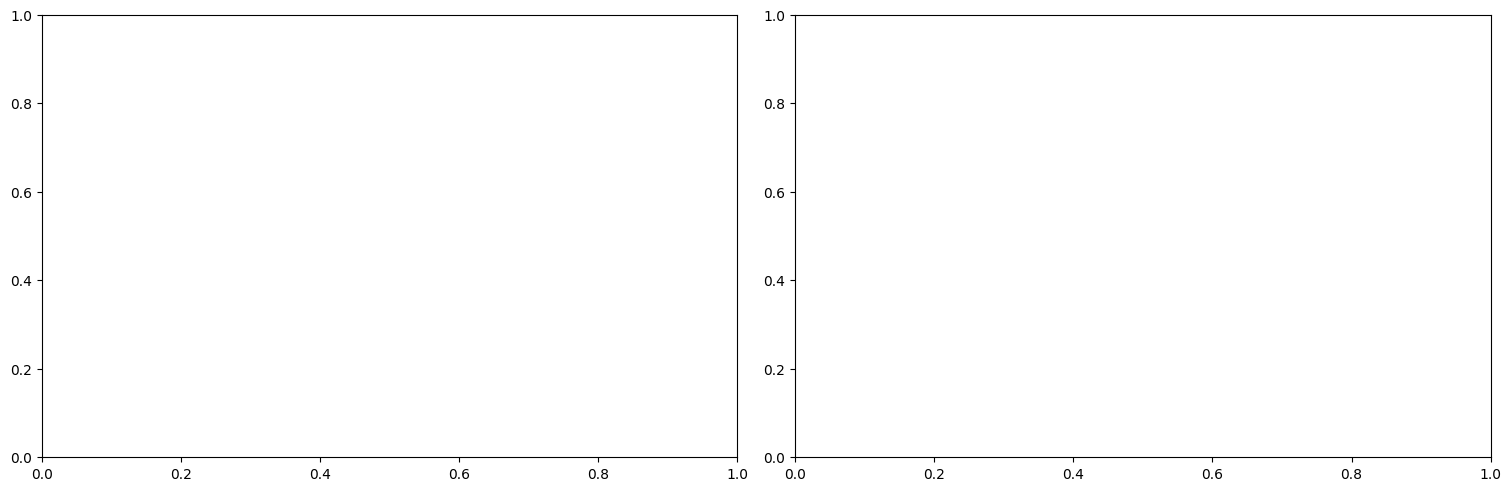

In [2]:
# Convergence and Stage 2 handoff gate. Run after Cell 13 has synchronized history.
# Stage 1 anneals 2e-4 to 2e-5 over 50 epochs. Stage 2 must begin at exactly
# 2e-5, then anneal further; no learning-rate restart is permitted.
STAGE_1_INITIAL_LR = 2.0e-4
STAGE_1_FINAL_LR = 2.0e-5
STAGE_2_INITIAL_LR = STAGE_1_FINAL_LR

histories = {label: load_run_history(run_name)[0] for label, run_name in RUNS.items()}
rows = []
figure, axes = plt.subplots(1, 2, figsize=(15, 4.8), constrained_layout=True)
for label, history in histories.items():
    if history.empty:
        continue
    stage_one = history[history["stage"] == 1]
    stage_two = history[history["stage"] == 2]
    if stage_one.empty:
        continue

    final_stage_one = stage_one.iloc[-1]
    best_stage_one = stage_one.loc[stage_one["val_loss"].idxmin()]
    rows.append({
        "model": label,
        "stage 1 epochs": len(stage_one),
        "stage 1 final validation": final_stage_one["val_loss"],
        "stage 1 best validation": best_stage_one["val_loss"],
        "stage 1 best epoch": int(best_stage_one["epoch"]),
        "stage 2 available": not stage_two.empty,
        "stage 2 initial LR": stage_two["initial_lr"].iloc[0] if not stage_two.empty else STAGE_2_INITIAL_LR,
        "LR handoff continuous": bool(stage_two.empty or np.isclose(stage_two["initial_lr"].iloc[0], STAGE_2_INITIAL_LR)),
    })
    axes[0].semilogy(stage_one["epoch"], 100 * stage_one["val_loss"], marker="s", markersize=3, label=f"{label} Stage 1")
    if not stage_two.empty:
        axes[0].semilogy(stage_two["global_epoch"], 100 * stage_two["val_loss"], marker="s", markersize=3, label=f"{label} Stage 2")
    axes[1].semilogy(stage_one["epoch"], 100 * stage_one["train_loss"], marker="o", markersize=3, label=f"{label} train")
    axes[1].semilogy(stage_one["epoch"], 100 * stage_one["val_loss"], marker="s", markersize=3, linestyle="--", label=f"{label} validation")

if not rows:
    print("No synchronized hybrid training history yet.")
else:
    display(pd.DataFrame(rows).style.format({
        "stage 1 final validation": "{:.4%}",
        "stage 1 best validation": "{:.4%}",
        "stage 2 initial LR": "{:.2e}",
    }))
    axes[0].set(title="Validation convergence across stages", xlabel="Stage 1 epoch / cumulative epoch", ylabel="Validation loss (%)")
    axes[1].set(title="Stage 1 generalization gap", xlabel="Stage 1 epoch", ylabel="Loss (%)")
    for axis in axes:
        axis.grid(True, which="both", alpha=0.25)
        axis.legend(frameon=False, fontsize=8)
    plt.show()
    print(f"Required Stage 1 to Stage 2 LR handoff: {STAGE_1_FINAL_LR:.2e} -> {STAGE_2_INITIAL_LR:.2e}.")
    print("Launch Stage 2 only when Stage 1 has completed and validation is stable or improving over its final 10 epochs.")

,run,source checkpoint,source,GPU configuration,wall cap (hours),planned epochs,completed epochs,validation split seed,training shuffle seed,latest validation (%),best validation (%),learning-rate range
0,Stage 2 reproduction from Stage 1 best,stage_01_best.pt,remote live log synchronized 2026-08-14 09:05:03 UTC,DDP on GPUs 0 and 1,10,4096,3845,227344,227344,0.3673,0.3672,2.00e-05 to 2.00e-07


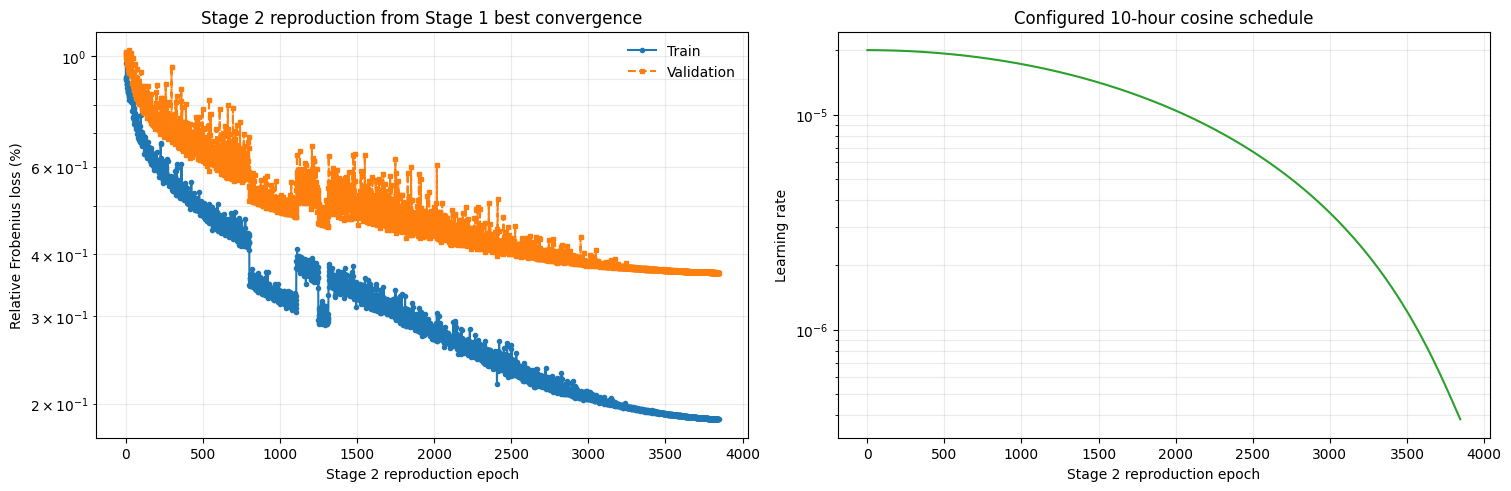

In [24]:
# Stage 2 reproduction one-pass tracker. Rerun this cell whenever you want an updated view.
import json
import os
import re
from datetime import datetime, timezone
from pathlib import Path
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "clean_simulation").is_dir():
    ROOT = ROOT.parent

REMOTE_HOST = "ubuntu@Sketch2Sim-cb7cf3a7878c4a07.elb.us-east-2.amazonaws.com"
SSH_KEY = Path(os.environ["USERPROFILE"]) / ".ssh" / "ibm_learning.pem"
RUN_NAME = "hybrid_parity_transformer_w256_l8_seed227344"
RUN_LABEL = "Stage 2 reproduction from Stage 1 best"
RUN_DIR = ROOT / "clean_simulation" / "outputs" / "adaptive_training" / RUN_NAME
STAGE_EPOCHS = 4096
STAGE_WALL_HOURS = 10
INITIAL_LR = 2.0e-5
FINAL_LR = 2.0e-7
SOURCE_CHECKPOINT = "stage_01_best.pt"
HISTORY_FILENAME = "stage_02_restart_history.json"
LOG_FILENAME = "stage_02_restart.log"
HISTORY_PATH = RUN_DIR / HISTORY_FILENAME
LOG_PATH = RUN_DIR / LOG_FILENAME
TEMPORARY_HISTORY = HISTORY_PATH.with_suffix(".json.part")
TEMPORARY_LOG = LOG_PATH.with_suffix(".log.part")
REMOTE_DIR = f"~/cutcell-training/clean_simulation/outputs/adaptive_training/{RUN_NAME}"
EPOCH_PATTERN = re.compile(r"Epoch\s+(\d+)/\d+\s+\| Train: ([0-9.eE+-]+) \| Val: ([0-9.eE+-]+)")

RUN_DIR.mkdir(parents=True, exist_ok=True)
for remote_name, temporary_path, local_path in (
    (HISTORY_FILENAME, TEMPORARY_HISTORY, HISTORY_PATH),
    (LOG_FILENAME, TEMPORARY_LOG, LOG_PATH),
):
    completed = subprocess.run(
        ["scp", "-q", "-i", str(SSH_KEY), f"{REMOTE_HOST}:{REMOTE_DIR}/{remote_name}", str(temporary_path)],
        capture_output=True,
        text=True,
    )
    if completed.returncode == 0:
        temporary_path.replace(local_path)

if not LOG_PATH.is_file():
    print(f"{RUN_LABEL} is initializing; rerun this cell after the first validation epoch.")
else:
    history_payload = {}
    if HISTORY_PATH.is_file():
        try:
            history_payload = json.loads(HISTORY_PATH.read_text(encoding="utf-8"))
        except json.JSONDecodeError:
            print("Latest checkpoint history was incomplete; displaying the live log instead.")

    rows = []
    for match in EPOCH_PATTERN.finditer(LOG_PATH.read_text(encoding="utf-8", errors="replace")):
        epoch, train_loss, val_loss = match.groups()
        rows.append({"epoch": int(epoch), "train_loss": float(train_loss), "val_loss": float(val_loss)})
    stage_history = pd.DataFrame(rows).drop_duplicates("epoch", keep="last").sort_values("epoch")
    if stage_history.empty:
        raise ValueError("The Stage 2 reproduction log has no completed epochs yet.")

    initial_lr = float(history_payload.get("initial_lr", INITIAL_LR))
    final_lr = FINAL_LR
    sync_time = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S UTC")
    summary = pd.DataFrame([{
        "run": RUN_LABEL,
        "source checkpoint": SOURCE_CHECKPOINT,
        "source": f"remote live log synchronized {sync_time}",
        "GPU configuration": "DDP on GPUs 0 and 1",
        "wall cap (hours)": STAGE_WALL_HOURS,
        "planned epochs": STAGE_EPOCHS,
        "completed epochs": int(stage_history["epoch"].max()),
        "validation split seed": history_payload.get("split_seed", 227344),
        "training shuffle seed": history_payload.get("shuffle_seed", 227344),
        "latest validation (%)": 100 * stage_history["val_loss"].iloc[-1],
        "best validation (%)": 100 * stage_history["val_loss"].min(),
        "learning-rate range": f"{initial_lr:.2e} to {final_lr:.2e}",
    }])
    display(summary.style.format({"latest validation (%)": "{:.4f}", "best validation (%)": "{:.4f}"}))

    figure, axes = plt.subplots(1, 2, figsize=(15, 4.8), constrained_layout=True)
    axes[0].semilogy(stage_history["epoch"], 100 * stage_history["train_loss"], marker="o", markersize=3, label="Train")
    axes[0].semilogy(stage_history["epoch"], 100 * stage_history["val_loss"], marker="s", markersize=3, linestyle="--", label="Validation")
    axes[0].set(title=f"{RUN_LABEL} convergence", xlabel="Stage 2 reproduction epoch", ylabel="Relative Frobenius loss (%)")
    axes[0].grid(True, which="both", alpha=0.25)
    axes[0].legend(frameon=False)

    progress = stage_history["epoch"] / STAGE_EPOCHS
    cosine_lr = final_lr + 0.5 * (initial_lr - final_lr) * (1.0 + np.cos(np.pi * progress))
    axes[1].semilogy(stage_history["epoch"], cosine_lr, color="tab:green")
    axes[1].set(title=f"Configured {STAGE_WALL_HOURS}-hour cosine schedule", xlabel="Stage 2 reproduction epoch", ylabel="Learning rate")
    axes[1].grid(True, which="both", alpha=0.25)
    plt.show()

Synchronized 2026-08-14 10:35:56 UTC


,run,status,optimizer,epochs,latest validation,best validation,latest LR
0,AdamW (GPU 0),running or complete,adamw,91,0.5737%,0.5712%,4.99e-06
1,L-BFGS (GPU 1),running or complete,lbfgs,34,0.7772%,0.7772%,2.00e-01


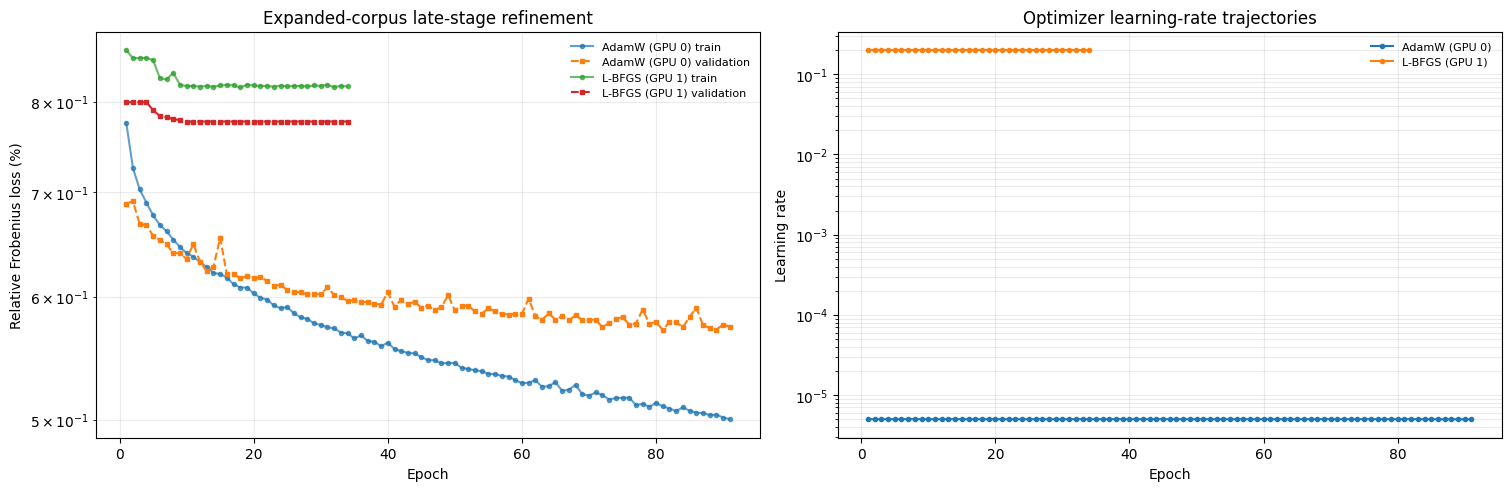

In [28]:
# Dual late-stage refinement tracker. Rerun after the expanded-data jobs have started.
import json
import os
import re
from datetime import datetime, timezone
from pathlib import Path
import subprocess

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "clean_simulation").is_dir():
    ROOT = ROOT.parent

REMOTE_HOST = "ubuntu@Sketch2Sim-cb7cf3a7878c4a07.elb.us-east-2.amazonaws.com"
SSH_KEY = Path(os.environ["USERPROFILE"]) / ".ssh" / "ibm_learning.pem"
RUNS = {
    "AdamW (GPU 0)": "stage_03_expanded_adamw",
    "L-BFGS (GPU 1)": "stage_03_expanded_lbfgs",
}
RUN_ROOT = "~/cutcell-training/clean_simulation/outputs/adaptive_training/hybrid_parity_transformer_w256_l8_seed227344"
EPOCH_PATTERN = re.compile(r"Epoch\s+(\d+)\s*/\s*\d+\s+\| Train: ([0-9.eE+-]+) \| Val: ([0-9.eE+-]+).*?Lr: ([0-9.eE+-]+)")

local_root = ROOT / "clean_simulation" / "outputs" / "adaptive_training" / "hybrid_parity_transformer_w256_l8_seed227344"
local_root.mkdir(parents=True, exist_ok=True)
histories = {}
status_rows = []

for label, run_name in RUNS.items():
    local_dir = local_root / run_name
    local_dir.mkdir(parents=True, exist_ok=True)
    remote_log = f"{RUN_ROOT}/{run_name}.log"
    remote_history = f"{RUN_ROOT}/{run_name}_history.json"
    local_log = local_dir / "training.log"
    local_history = local_dir / "history.json"

    for remote_path, local_path in ((remote_log, local_log), (remote_history, local_history)):
        temporary_path = local_path.with_suffix(local_path.suffix + ".part")
        completed = subprocess.run(
            ["scp", "-q", "-i", str(SSH_KEY), f"{REMOTE_HOST}:{remote_path}", str(temporary_path)],
            capture_output=True,
            text=True,
        )
        if completed.returncode == 0:
            temporary_path.replace(local_path)
        else:
            temporary_path.unlink(missing_ok=True)

    if not local_log.is_file():
        status_rows.append({"run": label, "status": "waiting for launch", "epochs": 0, "latest validation": None, "best validation": None})
        continue

    rows = [
        {"epoch": int(epoch), "train_loss": float(train), "val_loss": float(validation), "learning_rate": float(learning_rate)}
        for epoch, train, validation, learning_rate in EPOCH_PATTERN.findall(local_log.read_text(encoding="utf-8", errors="replace"))
    ]
    if not rows:
        status_rows.append({"run": label, "status": "initializing", "epochs": 0, "latest validation": None, "best validation": None})
        continue

    history = pd.DataFrame(rows).drop_duplicates("epoch", keep="last").sort_values("epoch")
    metadata = {}
    if local_history.is_file():
        try:
            metadata = json.loads(local_history.read_text(encoding="utf-8"))
        except json.JSONDecodeError:
            pass
    histories[label] = history
    status_rows.append({
        "run": label,
        "status": "running or complete",
        "optimizer": metadata.get("optimizer_type", label.split()[0].lower()),
        "epochs": int(history["epoch"].max()),
        "latest validation": history["val_loss"].iloc[-1],
        "best validation": history["val_loss"].min(),
        "latest LR": history["learning_rate"].iloc[-1],
    })

sync_time = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S UTC")
print(f"Synchronized {sync_time}")
display(pd.DataFrame(status_rows).style.format({"latest validation": "{:.4%}", "best validation": "{:.4%}", "latest LR": "{:.2e}"}, na_rep="--"))

if histories:
    figure, axes = plt.subplots(1, 2, figsize=(15, 4.8), constrained_layout=True)
    for label, history in histories.items():
        axes[0].semilogy(history["epoch"], 100 * history["train_loss"], marker="o", markersize=3, alpha=0.7, label=f"{label} train")
        axes[0].semilogy(history["epoch"], 100 * history["val_loss"], marker="s", markersize=3, linestyle="--", label=f"{label} validation")
        axes[1].semilogy(history["epoch"], history["learning_rate"], marker="o", markersize=3, label=label)
    axes[0].set(title="Expanded-corpus late-stage refinement", xlabel="Epoch", ylabel="Relative Frobenius loss (%)")
    axes[1].set(title="Optimizer learning-rate trajectories", xlabel="Epoch", ylabel="Learning rate")
    for axis in axes:
        axis.grid(True, which="both", alpha=0.25)
        axis.legend(frameon=False, fontsize=8)
    plt.show()

,checkpoint,geometry_kind,samples,mean,median,p90,p95,p99,p999
0,"AdamW, 30 minutes",original,114752,0.7425%,0.2173%,0.8869%,1.4552%,4.7630%,84.8999%
1,"AdamW, 30 minutes",transformed,119059,0.7056%,0.2793%,1.1476%,1.8252%,6.3382%,41.7046%
2,Stage 2 checkpoint,original,114752,1.0700%,0.2471%,1.2210%,1.9390%,5.0779%,130.0104%
3,Stage 2 checkpoint,transformed,119059,1.0440%,0.3170%,1.5631%,2.4360%,8.3258%,59.5557%


Largest geometry-level contributors to the validation loss:


,checkpoint,geometry_kind,geometry_name,samples,mean,median,p95,p99,loss_mass,loss_mass_share
31,"AdamW, 30 minutes",original,eggcarton_sphere,6522,2.0247%,0.4065%,3.3968%,20.2355%,132.050465,7.80%
48,"AdamW, 30 minutes",transformed,eggcarton_sphere_trans_6,6906,1.4484%,0.3862%,3.2321%,19.0403%,100.029122,5.91%
45,"AdamW, 30 minutes",transformed,eggcarton_sphere_trans_3,6759,1.2357%,0.3914%,2.9693%,12.1688%,83.518540,4.94%
43,"AdamW, 30 minutes",transformed,eggcarton_sphere_trans_1,6722,1.2277%,0.4101%,3.5527%,13.8586%,82.526196,4.88%
47,"AdamW, 30 minutes",transformed,eggcarton_sphere_trans_5,6839,1.2044%,0.3916%,3.2240%,17.6168%,82.368755,4.87%
46,"AdamW, 30 minutes",transformed,eggcarton_sphere_trans_4,6739,1.2097%,0.3816%,3.1012%,13.9844%,81.523874,4.82%
44,"AdamW, 30 minutes",transformed,eggcarton_sphere_trans_2,6691,1.1325%,0.4071%,3.3288%,13.8019%,75.778091,4.48%
18,"AdamW, 30 minutes",original,crystal_0017,3233,1.1091%,0.2221%,1.5173%,6.4787%,35.858239,2.12%
9,"AdamW, 30 minutes",original,crystal_0008,3137,1.0848%,0.1971%,1.4517%,12.7222%,34.030223,2.01%
16,"AdamW, 30 minutes",original,crystal_0015,3666,0.8872%,0.1945%,1.3572%,6.5912%,32.523642,1.92%


,checkpoint,volume_bin,samples,mean,p99,loss_mass,loss_mass_share
0,"AdamW, 30 minutes","(-0.001, 0.005]",9469,1.4627%,6.1132%,138.505982,8.19%
1,"AdamW, 30 minutes","(0.005, 0.02]",13853,1.9530%,9.4756%,270.550377,15.99%
2,"AdamW, 30 minutes","(0.02, 0.05]",13762,1.3801%,8.2434%,189.930367,11.22%
3,"AdamW, 30 minutes","(0.05, 0.15]",23925,1.0751%,7.2785%,257.223271,15.20%
4,"AdamW, 30 minutes","(0.15, 0.5]",52824,0.8318%,8.1765%,439.404428,25.97%
5,"AdamW, 30 minutes","(0.5, 0.85]",50969,0.5270%,5.6637%,268.599998,15.87%
6,"AdamW, 30 minutes","(0.85, 0.98]",36252,0.2485%,2.2924%,90.102501,5.32%
7,"AdamW, 30 minutes","(0.98, 1.0]",32757,0.1154%,0.7100%,37.815454,2.23%
8,Stage 2 checkpoint,"(-0.001, 0.005]",9469,3.4835%,9.3764%,329.856625,13.35%
9,Stage 2 checkpoint,"(0.005, 0.02]",13853,3.5059%,13.5507%,485.670385,19.66%


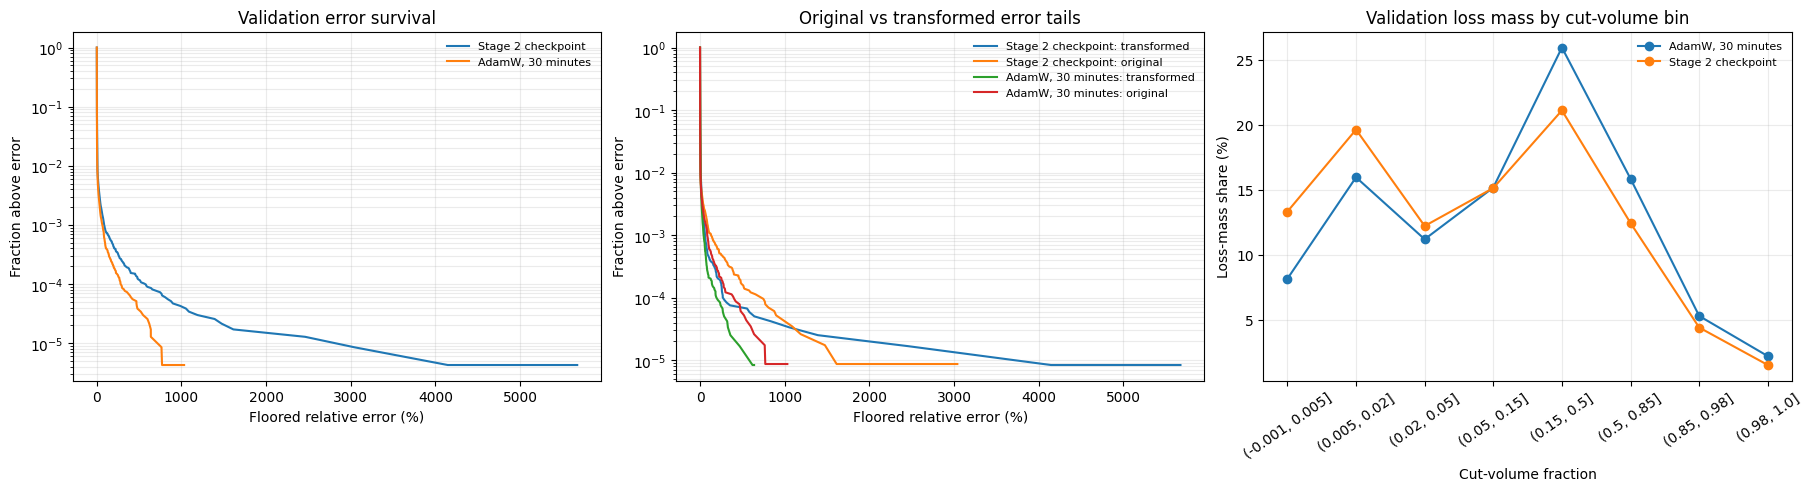

Worst individual validation rows. Use raw error only as a conditioning diagnostic; model selection uses the floored error.


,checkpoint,row_index,geometry_name,cut_volume_fraction,sdf_span,target_frobenius_norm,error_frobenius_norm,raw_relative_frobenius_error,floored_relative_frobenius_error
218919,Stage 2 checkpoint,2233643,eggcarton_sphere_trans_6,0.1449%,0.654782,0.007405,1.660368,22423.7610%,5676.2490%
22242,Stage 2 checkpoint,1580857,eggcarton_sphere_trans_3,0.2653%,0.733698,0.013068,1.213013,9282.1950%,4146.8876%
25154,Stage 2 checkpoint,711329,crystal_0015,0.6389%,0.610166,0.029604,0.900006,3040.1037%,3040.1037%
77784,Stage 2 checkpoint,1188361,eggcarton_sphere_trans_1,0.5104%,0.431432,0.023376,0.719862,3079.4966%,2460.9709%
123252,Stage 2 checkpoint,440500,crystal_0006,2.7912%,0.496103,0.089569,1.445501,1613.8450%,1613.8450%
15469,Stage 2 checkpoint,497432,crystal_0008,2.4808%,0.511511,0.087880,1.296571,1475.3900%,1475.3900%
117903,Stage 2 checkpoint,2189192,eggcarton_sphere_trans_6,0.1795%,0.230509,0.008173,0.407327,4983.6372%,1392.5162%
197011,Stage 2 checkpoint,491514,crystal_0008,2.9795%,0.499241,0.098008,1.165979,1189.6772%,1189.6772%
84412,Stage 2 checkpoint,274311,crystal_0001,0.9441%,0.539081,0.042374,0.460971,1087.8704%,1087.8704%
53519,Stage 2 checkpoint,2017082,eggcarton_sphere_trans_5,0.2421%,0.475946,0.012272,0.308311,2512.3419%,1054.0142%


In [29]:
# Expanded-corpus validation-error investigation. This compares the protected
# Stage 2 checkpoint with the 30-minute AdamW refinement on exactly the same
# deterministic expanded-data validation split.
import os
from pathlib import Path
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "clean_simulation").is_dir():
    ROOT = ROOT.parent

REMOTE_HOST = "ubuntu@Sketch2Sim-cb7cf3a7878c4a07.elb.us-east-2.amazonaws.com"
SSH_KEY = Path(os.environ["USERPROFILE"]) / ".ssh" / "ibm_learning.pem"
REMOTE_ANALYSIS_DIR = "~/cutcell-training/clean_simulation/outputs/analysis/transformed_hybrid_health"
LOCAL_ANALYSIS_DIR = ROOT / "clean_simulation" / "outputs" / "analysis" / "transformed_hybrid_health"
LOCAL_ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
DISTRIBUTIONS = {
    "Stage 2 checkpoint": "previous_stage_2_validation_loss_distribution.csv",
    "AdamW, 30 minutes": "adamw_30min_validation_loss_distribution.csv",
}

samples = []
for label, filename in DISTRIBUTIONS.items():
    local_path = LOCAL_ANALYSIS_DIR / filename
    temporary_path = local_path.with_suffix(".csv.part")
    completed = subprocess.run(
        ["scp", "-q", "-i", str(SSH_KEY), f"{REMOTE_HOST}:{REMOTE_ANALYSIS_DIR}/{filename}", str(temporary_path)],
        capture_output=True,
        text=True,
    )
    if completed.returncode != 0:
        raise RuntimeError(f"Could not synchronize {filename}: {completed.stderr.strip()}")
    temporary_path.replace(local_path)
    samples.append(pd.read_csv(local_path).assign(checkpoint=label))

errors = pd.concat(samples, ignore_index=True)
errors["geometry_kind"] = np.where(errors["geometry_name"].str.contains("_trans_"), "transformed", "original")
errors["volume_bin"] = pd.cut(
    errors["cut_volume_fraction"],
    bins=[0.0, 0.005, 0.02, 0.05, 0.15, 0.5, 0.85, 0.98, 1.0],
    include_lowest=True,
)
metric = "floored_relative_frobenius_error"

summary = errors.groupby(["checkpoint", "geometry_kind"])[metric].agg(
    samples="size",
    mean="mean",
    median="median",
    p90=lambda values: values.quantile(0.90),
    p95=lambda values: values.quantile(0.95),
    p99=lambda values: values.quantile(0.99),
    p999=lambda values: values.quantile(0.999),
).reset_index()
display(summary.style.format({column: "{:.4%}" for column in summary.columns if column not in {"checkpoint", "geometry_kind", "samples"}}))

geometry_summary = errors.groupby(["checkpoint", "geometry_kind", "geometry_name"])[metric].agg(
    samples="size",
    mean="mean",
    median="median",
    p95=lambda values: values.quantile(0.95),
    p99=lambda values: values.quantile(0.99),
    loss_mass="sum",
).reset_index()
geometry_summary["loss_mass_share"] = geometry_summary["loss_mass"] / geometry_summary.groupby("checkpoint")["loss_mass"].transform("sum")
print("Largest geometry-level contributors to the validation loss:")
display(
    geometry_summary.sort_values(["checkpoint", "loss_mass_share"], ascending=[True, False])
    .groupby("checkpoint", group_keys=False).head(15)
    .style.format({"mean": "{:.4%}", "median": "{:.4%}", "p95": "{:.4%}", "p99": "{:.4%}", "loss_mass_share": "{:.2%}"})
)

volume_summary = errors.groupby(["checkpoint", "volume_bin"], observed=True)[metric].agg(
    samples="size",
    mean="mean",
    p99=lambda values: values.quantile(0.99),
    loss_mass="sum",
).reset_index()
volume_summary["loss_mass_share"] = volume_summary["loss_mass"] / volume_summary.groupby("checkpoint")["loss_mass"].transform("sum")
display(volume_summary.style.format({"mean": "{:.4%}", "p99": "{:.4%}", "loss_mass_share": "{:.2%}"}))

figure, axes = plt.subplots(1, 3, figsize=(18, 4.8), constrained_layout=True)
for label, values in errors.groupby("checkpoint", sort=False):
    ordered = np.sort(values[metric].to_numpy())
    survival = 1.0 - np.arange(1, len(ordered) + 1) / len(ordered)
    axes[0].semilogy(100 * ordered, np.maximum(survival, 1.0 / len(ordered)), label=label)
for (label, kind), values in errors.groupby(["checkpoint", "geometry_kind"], sort=False):
    ordered = np.sort(values[metric].to_numpy())
    survival = 1.0 - np.arange(1, len(ordered) + 1) / len(ordered)
    axes[1].semilogy(100 * ordered, np.maximum(survival, 1.0 / len(ordered)), label=f"{label}: {kind}")
for label, values in volume_summary.groupby("checkpoint", sort=False):
    axes[2].plot(values["volume_bin"].astype(str), 100 * values["loss_mass_share"], marker="o", label=label)
axes[0].set(title="Validation error survival", xlabel="Floored relative error (%)", ylabel="Fraction above error")
axes[1].set(title="Original vs transformed error tails", xlabel="Floored relative error (%)", ylabel="Fraction above error")
axes[2].set(title="Validation loss mass by cut-volume bin", xlabel="Cut-volume fraction", ylabel="Loss-mass share (%)")
for axis in axes:
    axis.grid(True, which="both", alpha=0.25)
    axis.legend(frameon=False, fontsize=8)
axes[2].tick_params(axis="x", rotation=35)
plt.show()

worst_rows = errors.sort_values(metric, ascending=False).groupby("checkpoint", group_keys=False).head(20)
print("Worst individual validation rows. Use raw error only as a conditioning diagnostic; model selection uses the floored error.")
display(worst_rows[[
    "checkpoint", "row_index", "geometry_name", "cut_volume_fraction", "sdf_span",
    "target_frobenius_norm", "error_frobenius_norm", "raw_relative_frobenius_error", metric,
]].style.format({
    "cut_volume_fraction": "{:.4%}", "raw_relative_frobenius_error": "{:.4%}", metric: "{:.4%}",
    "sdf_span": "{:.6f}", "target_frobenius_norm": "{:.6f}", "error_frobenius_norm": "{:.6f}",
}))

In [34]:
# Hidden-variable audit: local target ambiguity in the eight-SDF representation.
# If almost identical eight-distance inputs have very different stiffness targets,
# the omitted local geometry/topology is a measurable latent variable.
import base64
import json

from IPython.display import display

RUN_LABEL = "AdamW, 30 minutes"
RUN_ERRORS = errors.loc[errors["checkpoint"] == RUN_LABEL].copy()
AUDIT_GEOMETRIES = [
    "eggcarton_sphere",
    "eggcarton_sphere_trans_1",
    "eggcarton_sphere_trans_2",
    "eggcarton_sphere_trans_3",
    "eggcarton_sphere_trans_4",
    "eggcarton_sphere_trans_5",
    "eggcarton_sphere_trans_6",
    "crystal_0017",
    "crystal_0008",
    "crystal_0010",
    "crystal_0015",
    "crystal_0018",
    "crystal_0022",
]
SAMPLES_PER_GEOMETRY = 400
REMOTE_DATA_PATH = "clean_simulation/outputs/data/grid_locked_source_magnitude_material_parity_rebuilt_queso_i2_p1_simple_harsh_crystals30_transformed_filtered.h5"
REMOTE_OUTPUT = "clean_simulation/outputs/analysis/transformed_hybrid_health/adamw_hidden_variable_neighbor_audit.csv"
REMOTE_MANIFEST = "/tmp/adamw_hidden_variable_manifest.json"
LOCAL_OUTPUT = LOCAL_ANALYSIS_DIR / "adamw_hidden_variable_neighbor_audit.csv"
LOCAL_MANIFEST = LOCAL_ANALYSIS_DIR / "adamw_hidden_variable_manifest.json"

selected_parts = []
for _, values in RUN_ERRORS[RUN_ERRORS["geometry_name"].isin(AUDIT_GEOMETRIES)].groupby("geometry_name"):
    selected_parts.append(values.nlargest(SAMPLES_PER_GEOMETRY // 2, metric))
    selected_parts.append(values.nsmallest(SAMPLES_PER_GEOMETRY // 2, metric))
selected = pd.concat(selected_parts, ignore_index=True).drop_duplicates("row_index")
selected_rows = selected[["row_index", "geometry_name", metric]].to_dict("records")
LOCAL_MANIFEST.write_text(json.dumps(selected_rows), encoding="utf-8")

completed = subprocess.run(
    ["scp", "-q", "-i", str(SSH_KEY), str(LOCAL_MANIFEST), f"{REMOTE_HOST}:{REMOTE_MANIFEST}"],
    capture_output=True,
    text=True,
)
if completed.returncode != 0:
    raise RuntimeError(f"Could not transfer hidden-variable manifest: {completed.stderr.strip()}")

remote_program = f'''\
import csv
import json
from pathlib import Path

import h5py
import numpy as np
from scipy.spatial import cKDTree

DATA_PATH = Path({REMOTE_DATA_PATH!r})
OUTPUT_PATH = Path({REMOTE_OUTPUT!r})
SELECTED_ROWS = json.loads(Path({REMOTE_MANIFEST!r}).read_text(encoding="utf-8"))

by_geometry = {{}}
for row in SELECTED_ROWS:
    by_geometry.setdefault(row["geometry_name"], []).append(row)

with h5py.File(DATA_PATH, "r") as handle:
    group = handle["integration_2_poly_1"]
    names = np.asarray(group["geometry_name"]).astype(str)
    d_values = group["d_values"]
    targets = group["stiffness_ut"]
    output_rows = []
    for geometry_name, requested in by_geometry.items():
        indices = np.flatnonzero(names == geometry_name)
        features = np.asarray(d_values[indices], dtype=np.float64)
        target_values = np.asarray(targets[indices], dtype=np.float64)
        tree = cKDTree(features)
        global_to_local = {{int(global_index): local_index for local_index, global_index in enumerate(indices)}}
        for row in requested:
            row_index = int(row["row_index"])
            local_index = global_to_local[row_index]
            distances, neighbors = tree.query(features[local_index], k=2)
            neighbor_index = int(neighbors[1])
            target = target_values[local_index]
            neighbor_target = target_values[neighbor_index]
            target_norm = float(np.linalg.norm(target))
            difference_norm = float(np.linalg.norm(target - neighbor_target))
            output_rows.append({{
                "row_index": row_index,
                "geometry_name": geometry_name,
                "floored_relative_error": float(row[{metric!r}]),
                "nearest_sdf_distance": float(distances[1]),
                "target_neighbor_difference_norm": difference_norm,
                "target_neighbor_difference_relative": difference_norm / max(target_norm, 1e-12),
                "target_norm": target_norm,
                "neighbor_row_index": int(indices[neighbor_index]),
            }})

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
with OUTPUT_PATH.open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(output_rows[0]))
    writer.writeheader()
    writer.writerows(output_rows)
print(json.dumps({{"rows": len(output_rows), "output": str(OUTPUT_PATH)}}))
'''
encoded_program = base64.b64encode(remote_program.encode("utf-8")).decode("ascii")
completed = subprocess.run(
    [
        "ssh", "-o", "ConnectTimeout=15", "-i", str(SSH_KEY), REMOTE_HOST,
        f"cd ~/cutcell-training; echo {encoded_program} | base64 -d | ~/.venvs/cutcell/bin/python -",
    ],
    capture_output=True,
    text=True,
)
if completed.returncode != 0:
    raise RuntimeError(completed.stderr.strip())
print(completed.stdout.strip())

temporary_output = LOCAL_OUTPUT.with_suffix(".csv.part")
completed = subprocess.run(
    ["scp", "-q", "-i", str(SSH_KEY), f"{REMOTE_HOST}:~/{REMOTE_OUTPUT}", str(temporary_output)],
    capture_output=True,
    text=True,
)
if completed.returncode != 0:
    raise RuntimeError(f"Could not synchronize hidden-variable audit: {completed.stderr.strip()}")
temporary_output.replace(LOCAL_OUTPUT)
neighbor_audit = pd.read_csv(LOCAL_OUTPUT)

correlations = neighbor_audit[[
    "floored_relative_error",
    "nearest_sdf_distance",
    "target_neighbor_difference_norm",
    "target_neighbor_difference_relative",
    "target_norm",
]].corr(method="spearman")["floored_relative_error"].sort_values(ascending=False)
display(correlations.rename("Spearman correlation with floored relative error").to_frame())

figure, axes = plt.subplots(1, 3, figsize=(18, 4.8), constrained_layout=True)
for geometry_name, values in neighbor_audit.groupby("geometry_name"):
    axes[0].scatter(values["nearest_sdf_distance"], 100 * values["floored_relative_error"], s=12, alpha=0.5, label=geometry_name)
    axes[1].scatter(values["target_neighbor_difference_relative"], 100 * values["floored_relative_error"], s=12, alpha=0.5, label=geometry_name)
    axes[2].scatter(values["target_norm"], 100 * values["floored_relative_error"], s=12, alpha=0.5, label=geometry_name)
axes[0].set(xscale="log", yscale="log", title="Input-space isolation", xlabel="Nearest same-geometry eight-SDF distance", ylabel="Floored relative error (%)")
axes[1].set(xscale="log", yscale="log", title="Candidate hidden variable", xlabel="Relative target change to nearest SDF neighbor", ylabel="Floored relative error (%)")
axes[2].set(xscale="log", yscale="log", title="Target magnitude conditioning", xlabel="Target Frobenius norm", ylabel="Floored relative error (%)")
for axis in axes:
    axis.grid(True, which="both", alpha=0.25)
axes[1].legend(frameon=False, fontsize=6, ncol=2)
plt.show()

neighbor_audit["ambiguity_bin"] = pd.qcut(
    neighbor_audit["target_neighbor_difference_relative"],
    q=5,
    duplicates="drop",
)
display(
    neighbor_audit.groupby("ambiguity_bin", observed=True).agg(
        rows=("row_index", "size"),
        median_error=("floored_relative_error", "median"),
        mean_error=("floored_relative_error", "mean"),
        p95_error=("floored_relative_error", lambda values: values.quantile(0.95)),
        median_sdf_distance=("nearest_sdf_distance", "median"),
    ).style.format({
        "median_error": "{:.3%}", "mean_error": "{:.3%}", "p95_error": "{:.3%}", "median_sdf_distance": "{:.3e}",
    })
)
print("Interpretation: a positive correlation between error and nearest-neighbor target disagreement means the omitted geometry/topology is predictive of error beyond the eight visible SDF values.")

{"rows": 5200, "output": "clean_simulation/outputs/analysis/transformed_hybrid_health/adamw_hidden_variable_neighbor_audit.csv"}


RuntimeError: Could not synchronize hidden-variable audit: scp: ~/clean_simulation/outputs/analysis/transformed_hybrid_health/adamw_hidden_variable_neighbor_audit.csv: No such file or directory

,Spearman correlation with floored relative error
floored_relative_error,1.000000
target_neighbor_difference_relative,0.746103
target_neighbor_difference_norm,0.720716
nearest_sdf_distance,0.580360
target_norm,-0.682093


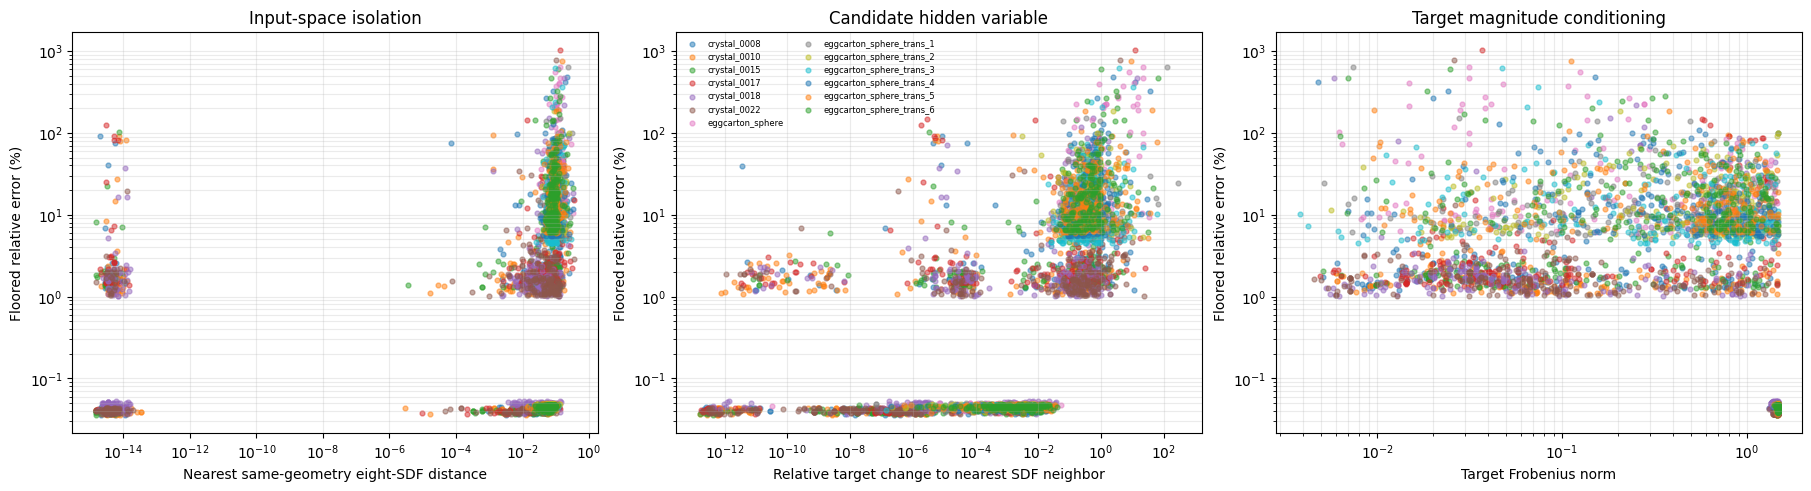

,rows,median_error,mean_error,p95_error,median_sdf_distance
ambiguity_bin,,,,,
"(-0.001, 2.96e-06]",1040,0.041%,0.792%,2.026%,4.082e-15
"(2.96e-06, 0.00145]",1040,0.046%,1.489%,2.039%,4.434e-02
"(0.00145, 0.0409]",1040,0.046%,1.015%,2.515%,5.783e-02
"(0.0409, 0.35]",1040,7.229%,11.794%,39.819%,7.889e-02
"(0.35, 278.484]",1040,9.577%,30.690%,99.113%,8.759e-02


Interpretation: a positive correlation between error and nearest-neighbor target disagreement means the omitted geometry/topology is predictive of error beyond the eight visible SDF values.


In [33]:
# Complete the hidden-variable audit after the remote calculation has written its CSV.
temporary_output = LOCAL_OUTPUT.with_suffix(".csv.part")
completed = subprocess.run(
    [
        "scp", "-q", "-i", str(SSH_KEY),
        f"{REMOTE_HOST}:~/cutcell-training/{REMOTE_OUTPUT}",
        str(temporary_output),
    ],
    capture_output=True,
    text=True,
)
if completed.returncode != 0:
    raise RuntimeError(f"Could not synchronize hidden-variable audit: {completed.stderr.strip()}")
temporary_output.replace(LOCAL_OUTPUT)
neighbor_audit = pd.read_csv(LOCAL_OUTPUT)

correlations = neighbor_audit[[
    "floored_relative_error",
    "nearest_sdf_distance",
    "target_neighbor_difference_norm",
    "target_neighbor_difference_relative",
    "target_norm",
]].corr(method="spearman")["floored_relative_error"].sort_values(ascending=False)
display(correlations.rename("Spearman correlation with floored relative error").to_frame())

figure, axes = plt.subplots(1, 3, figsize=(18, 4.8), constrained_layout=True)
for geometry_name, values in neighbor_audit.groupby("geometry_name"):
    axes[0].scatter(values["nearest_sdf_distance"], 100 * values["floored_relative_error"], s=12, alpha=0.5, label=geometry_name)
    axes[1].scatter(values["target_neighbor_difference_relative"], 100 * values["floored_relative_error"], s=12, alpha=0.5, label=geometry_name)
    axes[2].scatter(values["target_norm"], 100 * values["floored_relative_error"], s=12, alpha=0.5, label=geometry_name)
axes[0].set(xscale="log", yscale="log", title="Input-space isolation", xlabel="Nearest same-geometry eight-SDF distance", ylabel="Floored relative error (%)")
axes[1].set(xscale="log", yscale="log", title="Candidate hidden variable", xlabel="Relative target change to nearest SDF neighbor", ylabel="Floored relative error (%)")
axes[2].set(xscale="log", yscale="log", title="Target magnitude conditioning", xlabel="Target Frobenius norm", ylabel="Floored relative error (%)")
for axis in axes:
    axis.grid(True, which="both", alpha=0.25)
axes[1].legend(frameon=False, fontsize=6, ncol=2)
plt.show()

neighbor_audit["ambiguity_bin"] = pd.qcut(neighbor_audit["target_neighbor_difference_relative"], q=5, duplicates="drop")
ambiguity_summary = neighbor_audit.groupby("ambiguity_bin", observed=True).agg(
    rows=("row_index", "size"),
    median_error=("floored_relative_error", "median"),
    mean_error=("floored_relative_error", "mean"),
    p95_error=("floored_relative_error", lambda values: values.quantile(0.95)),
    median_sdf_distance=("nearest_sdf_distance", "median"),
)
display(ambiguity_summary.style.format({
    "median_error": "{:.3%}", "mean_error": "{:.3%}", "p95_error": "{:.3%}", "median_sdf_distance": "{:.3e}",
}))
print("Interpretation: a positive correlation between error and nearest-neighbor target disagreement means the omitted geometry/topology is predictive of error beyond the eight visible SDF values.")

Synchronized 2026-08-16 11:15:20 UTC


,run,GPU,process PID,initialization,input corpus,input contract,initial LR,planned epochs,completed epoch,latest validation,best validation,latest LR,history best
0,"Small (128-wide, 6-layer)",1,381015,Resumed from the small fresh-run epoch-18 checkpoint,exact_original_sdf_lattice_rebuilt_queso_i2_p1_all72.h5,8 original SDF values only,5.00e-06,3000,237,2.8078%,2.7937%,4.93e-06,2.7937%
1,"Medium (256-wide, 8-layer)",1,380630,Resumed from the protected medium epoch-1403 checkpoint,exact_original_sdf_lattice_rebuilt_queso_i2_p1_all72.h5,8 original SDF values only,5.00e-07,1000,237,0.2570%,0.2564%,4.40e-07,0.2564%


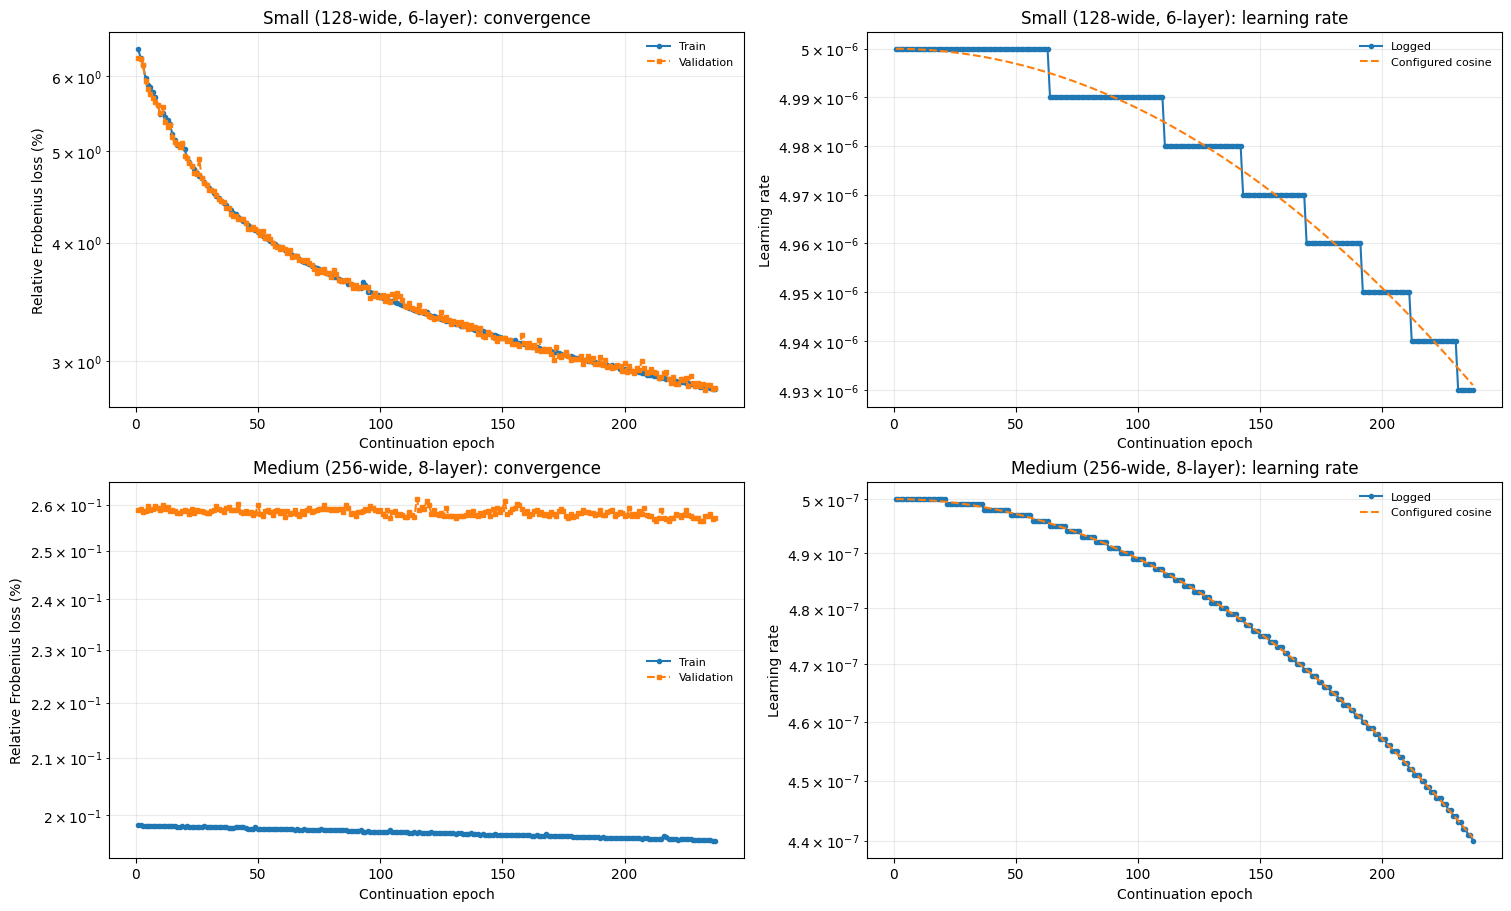

In [8]:
# Active exact-lattice Transformer tracker. Rerun this one-pass cell for a fresh snapshot of both GPU-1 runs.
import json
import os
import re
from datetime import datetime, timezone
from pathlib import Path
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "clean_simulation").is_dir():
    ROOT = ROOT.parent

REMOTE_HOST = "ubuntu@Sketch2Sim-cb7cf3a7878c4a07.elb.us-east-2.amazonaws.com"
SSH_KEY = Path(os.environ["USERPROFILE"]) / ".ssh" / "ibm_learning.pem"
RUNS = {
    "Small (128-wide, 6-layer)": {
        "name": "exact_lattice_transformer_w128_l6_ordered_sdf_from_epoch18_lr5e6_3000e_gpu1",
        "epochs": 3000, "initial_lr": 5.0e-6, "eta_min_factor": 0.1,
        "initialization": "Resumed from the small fresh-run epoch-18 checkpoint",
    },
    "Medium (256-wide, 8-layer)": {
        "name": "exact_lattice_transformer_w256_l8_ordered_sdf_from_epoch1403_lr5e7_1000e_gpu1",
        "epochs": 1000, "initial_lr": 5.0e-7, "eta_min_factor": 0.1,
        "initialization": "Resumed from the protected medium epoch-1403 checkpoint",
    },
}
DATASET = "exact_original_sdf_lattice_rebuilt_queso_i2_p1_all72.h5"
EPOCH_PATTERN = re.compile(r"Epoch\s+(\d+)\s*/\s*\d+\s+\| Train: ([0-9.eE+-]+) \| Val: ([0-9.eE+-]+).*?Lr: ([0-9.eE+-]+)")

histories, summary_rows = {}, []
for label, config in RUNS.items():
    run_name = config["name"]
    remote_dir = f"~/cutcell-training/clean_simulation/outputs/adaptive_training/{run_name}"
    local_dir = ROOT / "clean_simulation" / "outputs" / "adaptive_training" / run_name
    local_dir.mkdir(parents=True, exist_ok=True)
    for remote_name, local_name in (("training.log", "training.log"), ("stage_01_history.json", "history.json"), ("pid", "pid")):
        local_path = local_dir / local_name
        temporary_path = local_path.with_suffix(local_path.suffix + ".part")
        completed = subprocess.run(["scp", "-q", "-i", str(SSH_KEY), f"{REMOTE_HOST}:{remote_dir}/{remote_name}", str(temporary_path)], capture_output=True, text=True)
        if completed.returncode == 0:
            temporary_path.replace(local_path)
        else:
            temporary_path.unlink(missing_ok=True)
    log_path, history_path, pid_path = local_dir / "training.log", local_dir / "history.json", local_dir / "pid"
    log_text = log_path.read_text(encoding="utf-8", errors="replace") if log_path.is_file() else ""
    rows = [{"epoch": int(epoch), "train_loss": float(train), "val_loss": float(validation), "learning_rate": float(lr)} for epoch, train, validation, lr in EPOCH_PATTERN.findall(log_text)]
    history = pd.DataFrame(rows).drop_duplicates("epoch", keep="last").sort_values("epoch") if rows else pd.DataFrame()
    metadata = {}
    if history_path.is_file():
        try:
            metadata = json.loads(history_path.read_text(encoding="utf-8"))
        except json.JSONDecodeError:
            pass
    if not history.empty:
        histories[label] = history
    summary_rows.append({"run": label, "GPU": "1", "process PID": pid_path.read_text(encoding="utf-8").strip() if pid_path.is_file() else "unknown", "initialization": config["initialization"], "input corpus": DATASET, "input contract": "8 original SDF values only", "initial LR": config["initial_lr"], "planned epochs": config["epochs"], "completed epoch": int(history["epoch"].max()) if not history.empty else 0, "latest validation": history["val_loss"].iloc[-1] if not history.empty else None, "best validation": history["val_loss"].min() if not history.empty else None, "latest LR": history["learning_rate"].iloc[-1] if not history.empty else config["initial_lr"], "history best": metadata.get("best_val_loss")})

snapshot_time = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S UTC")
print(f"Synchronized {snapshot_time}")
display(pd.DataFrame(summary_rows).style.format({"initial LR": "{:.2e}", "latest validation": "{:.4%}", "best validation": "{:.4%}", "history best": "{:.4%}", "latest LR": "{:.2e}"}, na_rep="--"))

if not histories:
    print("Both workers are initializing; rerun after the first completed validation epoch.")
else:
    figure, axes = plt.subplots(len(histories), 2, figsize=(15, 4.5 * len(histories)), squeeze=False, constrained_layout=True)
    for row, (label, history) in enumerate(histories.items()):
        config = RUNS[label]
        loss_axis, lr_axis = axes[row]
        loss_axis.semilogy(history["epoch"], 100 * history["train_loss"], marker="o", markersize=3, label="Train")
        loss_axis.semilogy(history["epoch"], 100 * history["val_loss"], marker="s", markersize=3, linestyle="--", label="Validation")
        progress = history["epoch"] / config["epochs"]
        configured_lr = config["initial_lr"] * (config["eta_min_factor"] + 0.5 * (1.0 - config["eta_min_factor"]) * (1.0 + np.cos(np.pi * progress)))
        lr_axis.semilogy(history["epoch"], history["learning_rate"], marker="o", markersize=3, label="Logged")
        lr_axis.semilogy(history["epoch"], configured_lr, linestyle="--", label="Configured cosine")
        loss_axis.set(title=f"{label}: convergence", xlabel="Continuation epoch", ylabel="Relative Frobenius loss (%)")
        lr_axis.set(title=f"{label}: learning rate", xlabel="Continuation epoch", ylabel="Learning rate")
        for axis in (loss_axis, lr_axis):
            axis.grid(True, which="both", alpha=0.25)
            axis.legend(frameon=False, fontsize=8)
    plt.show()

wrote 69 summaries to clean_simulation/outputs/analysis/transformed_hybrid_health/mc_near_sdf_stiffness_difference_summary.csv


,sdf_distance_at_most,geometries,pairs,median_K_difference,worst_geometry_p95_K_difference,worst_geometry_max_K_difference,median_relative_K_difference,worst_geometry_p95_relative_K_difference,worst_geometry_max_relative_K_difference
0,1.0e-12,6,89579,0.00000,0.00001,1.24240,0.00%,0.01%,132.45%
1,1.0e-08,6,89579,0.00000,0.00001,1.24240,0.00%,0.01%,132.45%
2,1.0e-06,6,89579,0.00000,0.00001,1.24240,0.00%,0.01%,132.45%
3,1.0e-04,6,90458,0.00000,0.00001,1.24240,0.00%,0.01%,132.45%
4,1.0e-03,6,92796,0.00000,0.00001,1.24240,0.00%,0.01%,132.45%
5,1.0e-02,13,106799,0.00581,0.01894,1.24240,0.81%,13.37%,132.45%
6,5.0e-02,13,270860,0.02773,0.09533,1.24240,4.59%,42.69%,184.60%
7,1.0e-01,13,625924,0.04653,0.22091,1.38441,7.73%,73.21%,196.89%


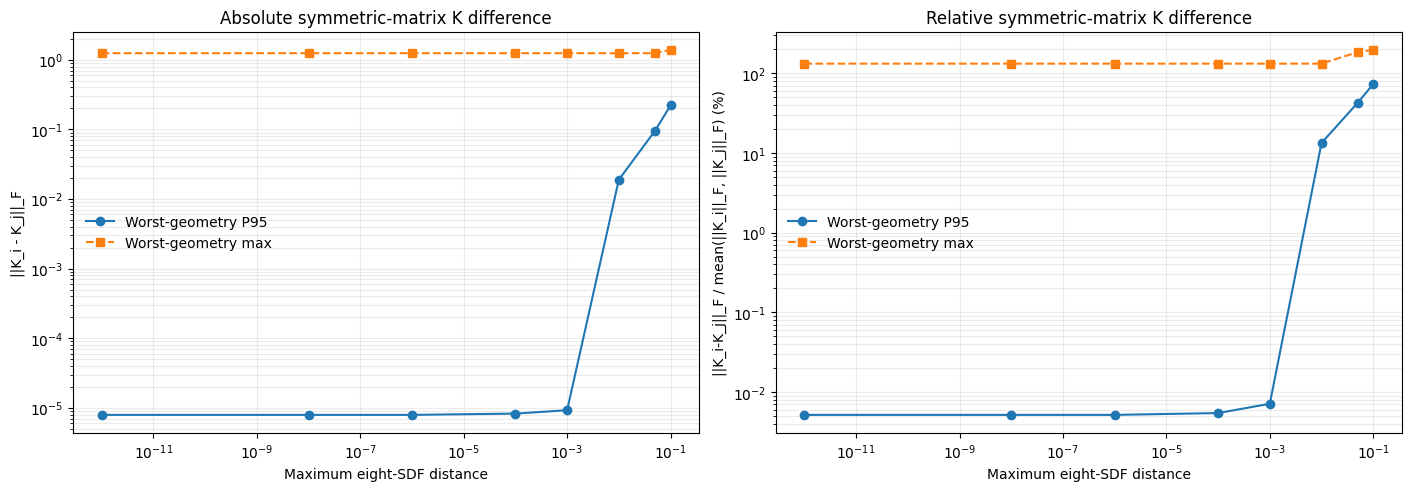

This reports target differences after marching-cubes reconstruction and QuESo assembly, not model prediction error.


In [36]:
# Quantify how much two reconstructed stiffness matrices K can differ when their
# eight hybrid SDF inputs are nearly equal. The target K values are the QuESo
# targets generated after the locked-grid marching-cubes reconstruction.
import base64

MC_DISTANCE_OUTPUT = "clean_simulation/outputs/analysis/transformed_hybrid_health/mc_near_sdf_stiffness_difference_summary.csv"
MC_DISTANCE_LOCAL = LOCAL_ANALYSIS_DIR / "mc_near_sdf_stiffness_difference_summary.csv"
MC_GEOMETRIES = AUDIT_GEOMETRIES

remote_program = f'''\
import csv
from pathlib import Path

import h5py
import numpy as np
from scipy.spatial import cKDTree

DATA_PATH = Path({REMOTE_DATA_PATH!r})
OUTPUT_PATH = Path({MC_DISTANCE_OUTPUT!r})
GEOMETRIES = {MC_GEOMETRIES!r}
THRESHOLDS = np.array([1e-12, 1e-8, 1e-6, 1e-4, 1e-3, 1e-2, 5e-2, 1e-1])
MATRIX_SIZE = 24
upper_i, upper_j = np.triu_indices(MATRIX_SIZE)
weights = np.where(upper_i == upper_j, 1.0, 2.0)

records = []
with h5py.File(DATA_PATH, "r") as handle:
    group = handle["integration_2_poly_1"]
    names = np.asarray(group["geometry_name"]).astype(str)
    for geometry_name in GEOMETRIES:
        indices = np.flatnonzero(names == geometry_name)
        features = np.asarray(group["d_values"][indices], dtype=np.float64)
        targets = np.asarray(group["stiffness_ut"][indices], dtype=np.float64)
        distances, neighbors = cKDTree(features).query(features, k=2)
        nearest_distance = distances[:, 1]
        partner = targets[neighbors[:, 1]]
        target_norm = np.sqrt(np.sum(weights * targets * targets, axis=1))
        partner_norm = np.sqrt(np.sum(weights * partner * partner, axis=1))
        difference_norm = np.sqrt(np.sum(weights * (targets - partner) ** 2, axis=1))
        relative_difference = difference_norm / np.maximum(0.5 * (target_norm + partner_norm), 1e-12)
        for threshold in THRESHOLDS:
            mask = nearest_distance <= threshold
            if not mask.any():
                continue
            values = difference_norm[mask]
            relative = relative_difference[mask]
            records.append({{
                "geometry_name": geometry_name,
                "sdf_distance_at_most": float(threshold),
                "pairs": int(mask.sum()),
                "median_K_difference": float(np.median(values)),
                "p95_K_difference": float(np.quantile(values, 0.95)),
                "max_K_difference": float(np.max(values)),
                "median_relative_K_difference": float(np.median(relative)),
                "p95_relative_K_difference": float(np.quantile(relative, 0.95)),
                "max_relative_K_difference": float(np.max(relative)),
            }})

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
with OUTPUT_PATH.open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(records[0]))
    writer.writeheader()
    writer.writerows(records)
print(f"wrote {{len(records)}} summaries to {{OUTPUT_PATH}}")
'''
encoded_program = base64.b64encode(remote_program.encode("utf-8")).decode("ascii")
completed = subprocess.run(
    ["ssh", "-o", "ConnectTimeout=15", "-i", str(SSH_KEY), REMOTE_HOST,
     f"cd ~/cutcell-training; echo {encoded_program} | base64 -d | ~/.venvs/cutcell/bin/python -"],
    capture_output=True,
    text=True,
)
if completed.returncode != 0:
    raise RuntimeError(completed.stderr.strip())
print(completed.stdout.strip())

temporary_output = MC_DISTANCE_LOCAL.with_suffix(".csv.part")
completed = subprocess.run(
    ["scp", "-q", "-i", str(SSH_KEY), f"{REMOTE_HOST}:~/cutcell-training/{MC_DISTANCE_OUTPUT}", str(temporary_output)],
    capture_output=True,
    text=True,
)
if completed.returncode != 0:
    raise RuntimeError(f"Could not synchronize MC K-difference summary: {completed.stderr.strip()}")
temporary_output.replace(MC_DISTANCE_LOCAL)
mc_difference = pd.read_csv(MC_DISTANCE_LOCAL)

aggregate = mc_difference.groupby("sdf_distance_at_most", as_index=False).agg(
    geometries=("geometry_name", "nunique"),
    pairs=("pairs", "sum"),
    median_K_difference=("median_K_difference", "median"),
    worst_geometry_p95_K_difference=("p95_K_difference", "max"),
    worst_geometry_max_K_difference=("max_K_difference", "max"),
    median_relative_K_difference=("median_relative_K_difference", "median"),
    worst_geometry_p95_relative_K_difference=("p95_relative_K_difference", "max"),
    worst_geometry_max_relative_K_difference=("max_relative_K_difference", "max"),
)
display(aggregate.style.format({
    "sdf_distance_at_most": "{:.1e}", "median_K_difference": "{:.5f}",
    "worst_geometry_p95_K_difference": "{:.5f}", "worst_geometry_max_K_difference": "{:.5f}",
    "median_relative_K_difference": "{:.2%}", "worst_geometry_p95_relative_K_difference": "{:.2%}",
    "worst_geometry_max_relative_K_difference": "{:.2%}",
}))

figure, axes = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True)
axes[0].loglog(aggregate["sdf_distance_at_most"], aggregate["worst_geometry_p95_K_difference"], marker="o", label="Worst-geometry P95")
axes[0].loglog(aggregate["sdf_distance_at_most"], aggregate["worst_geometry_max_K_difference"], marker="s", linestyle="--", label="Worst-geometry max")
axes[0].set(title="Absolute symmetric-matrix K difference", xlabel="Maximum eight-SDF distance", ylabel="||K_i - K_j||_F")
axes[1].loglog(aggregate["sdf_distance_at_most"], 100 * aggregate["worst_geometry_p95_relative_K_difference"], marker="o", label="Worst-geometry P95")
axes[1].loglog(aggregate["sdf_distance_at_most"], 100 * aggregate["worst_geometry_max_relative_K_difference"], marker="s", linestyle="--", label="Worst-geometry max")
axes[1].set(title="Relative symmetric-matrix K difference", xlabel="Maximum eight-SDF distance", ylabel="||K_i-K_j||_F / mean(||K_i||_F, ||K_j||_F) (%)")
for axis in axes:
    axis.grid(True, which="both", alpha=0.25)
    axis.legend(frameon=False)
plt.show()

print("This reports target differences after marching-cubes reconstruction and QuESo assembly, not model prediction error.")

wrote 8 orange-curve outliers to clean_simulation/outputs/analysis/transformed_hybrid_health/mc_near_sdf_outlier_configurations.csv


,sdf_distance_at_most,geometry_name,row_index,neighbor_row_index,sdf_l2_distance,sdf_max_corner_difference,K_difference_frobenius,relative_K_difference,case_code,neighbor_case_code,case_bits,neighbor_case_bits,inside_corners,neighbor_inside_corners,same_case_code
0,1.0e-12,crystal_0017,765185,776828,0.000e+00,0.000e+00,1.24240,132.45%,39,39,11100100,11100100,4,4,True
1,1.0e-08,crystal_0017,765185,776828,0.000e+00,0.000e+00,1.24240,132.45%,39,39,11100100,11100100,4,4,True
2,1.0e-06,crystal_0017,765185,776828,0.000e+00,0.000e+00,1.24240,132.45%,39,39,11100100,11100100,4,4,True
3,1.0e-04,crystal_0017,765185,776828,0.000e+00,0.000e+00,1.24240,132.45%,39,39,11100100,11100100,4,4,True
4,1.0e-03,crystal_0017,765185,776828,0.000e+00,0.000e+00,1.24240,132.45%,39,39,11100100,11100100,4,4,True
5,1.0e-02,crystal_0017,765185,776828,0.000e+00,0.000e+00,1.24240,132.45%,39,39,11100100,11100100,4,4,True
6,5.0e-02,crystal_0017,765185,776828,0.000e+00,0.000e+00,1.24240,132.45%,39,39,11100100,11100100,4,4,True
7,1.0e-01,eggcarton_sphere_trans_4,1808461,1809399,6.618e-02,4.278e-02,1.38441,135.59%,175,34,11110101,01000100,6,2,False


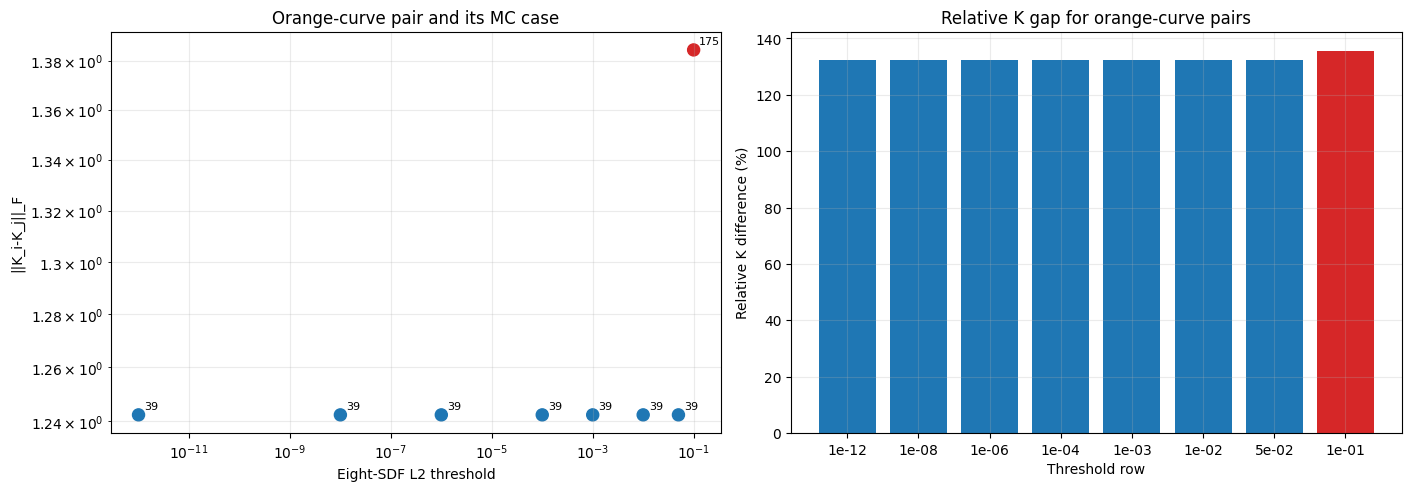

Blue: both cells have the same 8-corner case code. Red: their local material-sign configurations differ.
A matching code proves only the same corner-sign configuration; it does not prove identical reconstructed triangles or topology.


In [38]:
# Identify the marching-cubes corner-sign configuration behind the orange
# worst-case curve in Cell 21. A bit is 1 when the hybrid SDF is > 0.5, which
# is the material-inside side used by the locked-grid rebuilt geometry.
MC_OUTLIER_OUTPUT = "clean_simulation/outputs/analysis/transformed_hybrid_health/mc_near_sdf_outlier_configurations.csv"
MC_OUTLIER_LOCAL = LOCAL_ANALYSIS_DIR / "mc_near_sdf_outlier_configurations.csv"

remote_program = f'''\
import csv
from pathlib import Path

import h5py
import numpy as np
from scipy.spatial import cKDTree

DATA_PATH = Path({REMOTE_DATA_PATH!r})
OUTPUT_PATH = Path({MC_OUTLIER_OUTPUT!r})
GEOMETRIES = {MC_GEOMETRIES!r}
THRESHOLDS = np.array([1e-12, 1e-8, 1e-6, 1e-4, 1e-3, 1e-2, 5e-2, 1e-1])
upper_i, upper_j = np.triu_indices(24)
weights = np.where(upper_i == upper_j, 1.0, 2.0)

candidates = []
with h5py.File(DATA_PATH, "r") as handle:
    group = handle["integration_2_poly_1"]
    names = np.asarray(group["geometry_name"]).astype(str)
    for geometry_name in GEOMETRIES:
        indices = np.flatnonzero(names == geometry_name)
        features = np.asarray(group["d_values"][indices], dtype=np.float64)
        targets = np.asarray(group["stiffness_ut"][indices], dtype=np.float64)
        distances, neighbors = cKDTree(features).query(features, k=2)
        partner_indices = neighbors[:, 1]
        partners = targets[partner_indices]
        norms = np.sqrt(np.sum(weights * targets * targets, axis=1))
        partner_norms = np.sqrt(np.sum(weights * partners * partners, axis=1))
        differences = np.sqrt(np.sum(weights * (targets - partners) ** 2, axis=1))
        relative = differences / np.maximum(0.5 * (norms + partner_norms), 1e-12)
        mask = (features > 0.5).astype(np.uint8)
        case_code = np.sum(mask * (1 << np.arange(8, dtype=np.uint8)), axis=1)
        for threshold in THRESHOLDS:
            eligible = np.flatnonzero(distances[:, 1] <= threshold)
            if eligible.size == 0:
                continue
            local_index = eligible[np.argmax(differences[eligible])]
            partner_index = int(partner_indices[local_index])
            candidates.append({{
                "geometry_name": geometry_name,
                "sdf_distance_at_most": float(threshold),
                "row_index": int(indices[local_index]),
                "neighbor_row_index": int(indices[partner_index]),
                "sdf_l2_distance": float(distances[local_index, 1]),
                "sdf_max_corner_difference": float(np.max(np.abs(features[local_index] - features[partner_index]))),
                "K_difference_frobenius": float(differences[local_index]),
                "relative_K_difference": float(relative[local_index]),
                "case_code": int(case_code[local_index]),
                "neighbor_case_code": int(case_code[partner_index]),
                "case_bits": "".join(str(int(bit)) for bit in mask[local_index]),
                "neighbor_case_bits": "".join(str(int(bit)) for bit in mask[partner_index]),
                "inside_corners": int(mask[local_index].sum()),
                "neighbor_inside_corners": int(mask[partner_index].sum()),
                "same_case_code": bool(case_code[local_index] == case_code[partner_index]),
            }})

# The orange curve is max(max_K_difference) over geometry at each threshold.
# Retain exactly the responsible pair, with deterministic tie-breaking.
rows = []
for threshold in THRESHOLDS:
    eligible = [row for row in candidates if row["sdf_distance_at_most"] == float(threshold)]
    if eligible:
        rows.append(max(eligible, key=lambda row: (row["K_difference_frobenius"], -row["row_index"])))

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
with OUTPUT_PATH.open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)
print(f"wrote {{len(rows)}} orange-curve outliers to {{OUTPUT_PATH}}")
'''
encoded_program = base64.b64encode(remote_program.encode("utf-8")).decode("ascii")
completed = subprocess.run(
    ["ssh", "-o", "ConnectTimeout=15", "-i", str(SSH_KEY), REMOTE_HOST,
     f"cd ~/cutcell-training; echo {encoded_program} | base64 -d | ~/.venvs/cutcell/bin/python -"],
    capture_output=True,
    text=True,
)
if completed.returncode != 0:
    raise RuntimeError(completed.stderr.strip())
print(completed.stdout.strip())

temporary_output = MC_OUTLIER_LOCAL.with_suffix(".csv.part")
completed = subprocess.run(
    ["scp", "-q", "-i", str(SSH_KEY), f"{REMOTE_HOST}:~/cutcell-training/{MC_OUTLIER_OUTPUT}", str(temporary_output)],
    capture_output=True,
    text=True,
)
if completed.returncode != 0:
    raise RuntimeError(f"Could not synchronize MC configuration outliers: {completed.stderr.strip()}")
temporary_output.replace(MC_OUTLIER_LOCAL)
mc_outlier_cases = pd.read_csv(MC_OUTLIER_LOCAL, dtype={"case_bits": str, "neighbor_case_bits": str})

columns = [
    "sdf_distance_at_most", "geometry_name", "row_index", "neighbor_row_index",
    "sdf_l2_distance", "sdf_max_corner_difference", "K_difference_frobenius",
    "relative_K_difference", "case_code", "neighbor_case_code", "case_bits",
    "neighbor_case_bits", "inside_corners", "neighbor_inside_corners", "same_case_code",
]
display(mc_outlier_cases[columns].style.format({
    "sdf_distance_at_most": "{:.1e}", "sdf_l2_distance": "{:.3e}",
    "sdf_max_corner_difference": "{:.3e}", "K_difference_frobenius": "{:.5f}",
    "relative_K_difference": "{:.2%}",
}))

figure, axes = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True)
axes[0].scatter(
    mc_outlier_cases["sdf_distance_at_most"], mc_outlier_cases["K_difference_frobenius"],
    c=mc_outlier_cases["same_case_code"].map({True: "tab:blue", False: "tab:red"}), s=75,
)
for _, row in mc_outlier_cases.iterrows():
    axes[0].annotate(str(int(row["case_code"])), (row["sdf_distance_at_most"], row["K_difference_frobenius"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
axes[0].set(xscale="log", yscale="log", title="Orange-curve pair and its MC case", xlabel="Eight-SDF L2 threshold", ylabel="||K_i-K_j||_F")
axes[1].bar(range(len(mc_outlier_cases)), 100 * mc_outlier_cases["relative_K_difference"], color=np.where(mc_outlier_cases["same_case_code"], "tab:blue", "tab:red"))
axes[1].set(title="Relative K gap for orange-curve pairs", xlabel="Threshold row", ylabel="Relative K difference (%)")
axes[1].set_xticks(range(len(mc_outlier_cases)), [f"{value:.0e}" for value in mc_outlier_cases["sdf_distance_at_most"]])
for axis in axes:
    axis.grid(True, which="both", alpha=0.25)
plt.show()

print("Blue: both cells have the same 8-corner case code. Red: their local material-sign configurations differ.")
print("A matching code proves only the same corner-sign configuration; it does not prove identical reconstructed triangles or topology.")

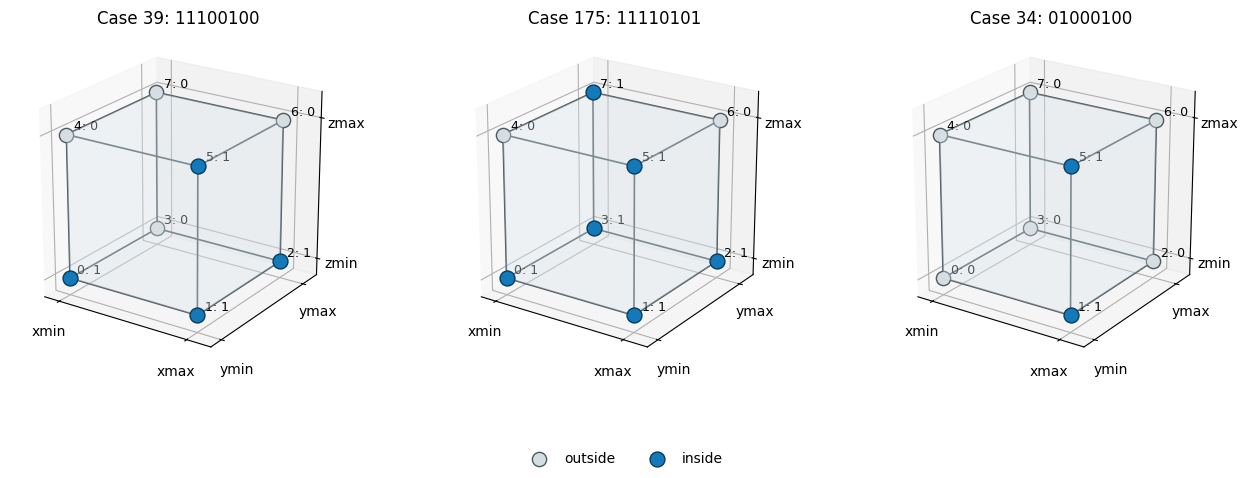

Each label is 'corner index: material bit'. The bit string is ordered from corner 0 through corner 7, not most-significant-bit first.
Case 39 is the blue outlier class; cases 175 and 34 form the red, case-changing outlier pair.


In [40]:
# Visual form of the corner-sign classes identified in Cell 22.
# The d_values ordering follows the hexahedron order used by QuESo:
# 0:(xmin,ymin,zmin), 1:(xmax,ymin,zmin), 2:(xmax,ymax,zmin), 3:(xmin,ymax,zmin),
# 4:(xmin,ymin,zmax), 5:(xmax,ymin,zmax), 6:(xmax,ymax,zmax), 7:(xmin,ymax,zmax).
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

CUBE_CORNERS = np.array([
    [0, 0, 0], [1, 0, 0], [1, 1, 0], [0, 1, 0],
    [0, 0, 1], [1, 0, 1], [1, 1, 1], [0, 1, 1],
], dtype=float)
CUBE_EDGES = (
    (0, 1), (1, 2), (2, 3), (3, 0),
    (4, 5), (5, 6), (6, 7), (7, 4),
    (0, 4), (1, 5), (2, 6), (3, 7),
)
CUBE_FACES = (
    (0, 1, 2, 3), (4, 5, 6, 7), (0, 1, 5, 4),
    (1, 2, 6, 5), (2, 3, 7, 6), (3, 0, 4, 7),
)

# Draw only the distinct configurations responsible for the orange curve.
case_definitions = []
for _, outlier in mc_outlier_cases.iterrows():
    for code, bits in ((outlier["case_code"], outlier["case_bits"]), (outlier["neighbor_case_code"], outlier["neighbor_case_bits"])):
        definition = (int(code), str(bits))
        if definition not in case_definitions:
            case_definitions.append(definition)


def draw_case(axis, case_code: int, case_bits: str) -> None:
    material = np.array([int(bit) for bit in case_bits], dtype=bool)
    face_collection = Poly3DCollection(
        [CUBE_CORNERS[list(face)] for face in CUBE_FACES],
        facecolors="#dce6eb", edgecolors="none", alpha=0.20,
    )
    axis.add_collection3d(face_collection)
    for start, end in CUBE_EDGES:
        axis.plot(*CUBE_CORNERS[[start, end]].T, color="#4b5961", linewidth=1.2)
    axis.scatter(*CUBE_CORNERS[~material].T, s=105, color="#d6dde0", edgecolor="#4b5961", depthshade=False, label="outside")
    axis.scatter(*CUBE_CORNERS[material].T, s=115, color="#1479b8", edgecolor="#083c5c", depthshade=False, label="inside")
    for corner, position in enumerate(CUBE_CORNERS):
        bit = int(material[corner])
        axis.text(*(position + np.array([0.035, 0.035, 0.035])), f"{corner}: {bit}", fontsize=9)
    axis.set(title=f"Case {case_code}: {case_bits}", xlim=(-0.12, 1.18), ylim=(-0.12, 1.18), zlim=(-0.12, 1.18))
    axis.set_box_aspect((1, 1, 1))
    axis.set_xticks([0, 1], ["xmin", "xmax"])
    axis.set_yticks([0, 1], ["ymin", "ymax"])
    axis.set_zticks([0, 1], ["zmin", "zmax"])
    axis.view_init(elev=22, azim=-56)

figure = plt.figure(figsize=(5.2 * len(case_definitions), 5.2))
for position, (case_code, case_bits) in enumerate(case_definitions, start=1):
    axis = figure.add_subplot(1, len(case_definitions), position, projection="3d")
    draw_case(axis, case_code, case_bits)

handles, labels = axis.get_legend_handles_labels()
figure.legend(handles, labels, loc="lower center", ncols=2, frameon=False)
figure.subplots_adjust(bottom=0.18, wspace=0.30)
plt.show()

print("Each label is 'corner index: material bit'. The bit string is ordered from corner 0 through corner 7, not most-significant-bit first.")
print("Case 39 is the blue outlier class; cases 175 and 34 form the red, case-changing outlier pair.")

wrote 4 SDF vectors to clean_simulation/outputs/analysis/transformed_hybrid_health/mc_outlier_pair_features.csv


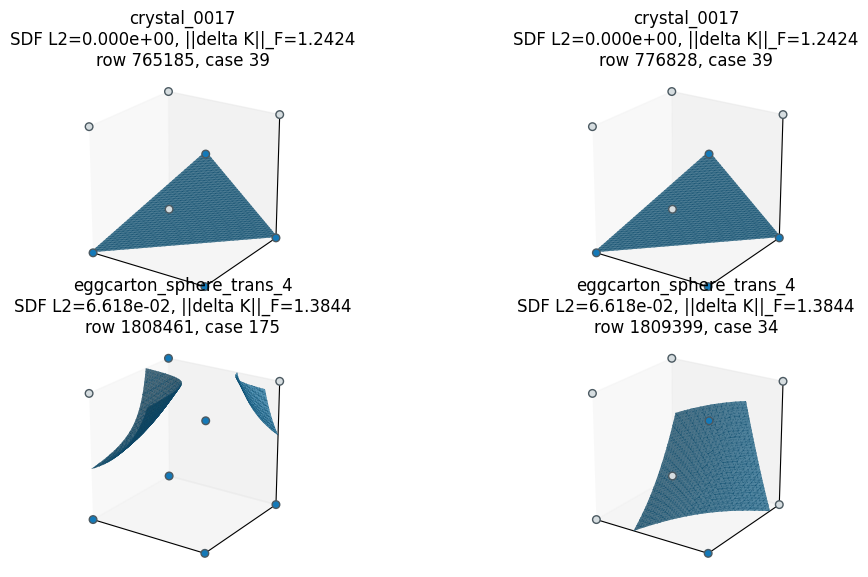

The top row is the exact-SDF case-39 pair: its two MC surfaces should coincide.
The bottom row is the close-SDF case-175 vs case-34 pair: its MC surfaces show the actual local geometry change.


In [43]:
# Reconstruct the local marching-cubes surface for the high-K-gap pairs.
# This applies MC to the eight stored hybrid SDF values via their trilinear
# interpolant; it is not a rendering of the full source or rebuilt mesh.
from skimage.measure import marching_cubes

MC_PAIR_FEATURE_OUTPUT = "clean_simulation/outputs/analysis/transformed_hybrid_health/mc_outlier_pair_features.csv"
MC_PAIR_FEATURE_LOCAL = LOCAL_ANALYSIS_DIR / "mc_outlier_pair_features.csv"
unique_outlier_pairs = mc_outlier_cases.drop_duplicates(["row_index", "neighbor_row_index"]).copy()
pair_rows = sorted({int(index) for pair in unique_outlier_pairs[["row_index", "neighbor_row_index"]].to_numpy() for index in pair})

remote_program = f'''\
import csv
from pathlib import Path

import h5py

DATA_PATH = Path({REMOTE_DATA_PATH!r})
OUTPUT_PATH = Path({MC_PAIR_FEATURE_OUTPUT!r})
ROW_INDICES = {pair_rows!r}

with h5py.File(DATA_PATH, "r") as handle:
    group = handle["integration_2_poly_1"]
    features = group["d_values"]
    names = group["geometry_name"]
    rows = []
    for row_index in ROW_INDICES:
        row = {{"row_index": row_index, "geometry_name": str(names[row_index], "utf-8") if isinstance(names[row_index], bytes) else str(names[row_index])}}
        row.update({{f"d{{corner}}": float(value) for corner, value in enumerate(features[row_index])}})
        rows.append(row)

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
with OUTPUT_PATH.open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=["row_index", "geometry_name"] + [f"d{{corner}}" for corner in range(8)])
    writer.writeheader()
    writer.writerows(rows)
print(f"wrote {{len(rows)}} SDF vectors to {{OUTPUT_PATH}}")
'''
encoded_program = base64.b64encode(remote_program.encode("utf-8")).decode("ascii")
completed = subprocess.run(
    ["ssh", "-o", "ConnectTimeout=15", "-i", str(SSH_KEY), REMOTE_HOST,
     f"cd ~/cutcell-training; echo {encoded_program} | base64 -d | ~/.venvs/cutcell/bin/python -"],
    capture_output=True,
    text=True,
)
if completed.returncode != 0:
    raise RuntimeError(completed.stderr.strip())
print(completed.stdout.strip())

temporary_output = MC_PAIR_FEATURE_LOCAL.with_suffix(".csv.part")
completed = subprocess.run(
    ["scp", "-q", "-i", str(SSH_KEY), f"{REMOTE_HOST}:~/cutcell-training/{MC_PAIR_FEATURE_OUTPUT}", str(temporary_output)],
    capture_output=True,
    text=True,
)
if completed.returncode != 0:
    raise RuntimeError(f"Could not synchronize MC pair features: {completed.stderr.strip()}")
temporary_output.replace(MC_PAIR_FEATURE_LOCAL)
mc_pair_features = pd.read_csv(MC_PAIR_FEATURE_LOCAL).set_index("row_index")

GRID_RESOLUTION = 41
coordinates = np.linspace(0.0, 1.0, GRID_RESOLUTION)
x_grid, y_grid, z_grid = np.meshgrid(coordinates, coordinates, coordinates, indexing="ij")


def trilinear_volume(corner_values: np.ndarray) -> np.ndarray:
    weights = np.stack((
        (1 - x_grid) * (1 - y_grid) * (1 - z_grid),
        x_grid * (1 - y_grid) * (1 - z_grid),
        x_grid * y_grid * (1 - z_grid),
        (1 - x_grid) * y_grid * (1 - z_grid),
        (1 - x_grid) * (1 - y_grid) * z_grid,
        x_grid * (1 - y_grid) * z_grid,
        x_grid * y_grid * z_grid,
        (1 - x_grid) * y_grid * z_grid,
    ), axis=-1)
    return np.einsum("...c,c->...", weights, corner_values)


def plot_mc_surface(axis, row_index: int, title: str) -> None:
    sdf = mc_pair_features.loc[row_index, [f"d{corner}" for corner in range(8)]].to_numpy(dtype=float)
    volume = trilinear_volume(sdf)
    vertices, faces, _, _ = marching_cubes(volume, level=0.5, spacing=(1 / (GRID_RESOLUTION - 1),) * 3)
    axis.plot_trisurf(vertices[:, 0], vertices[:, 1], faces, vertices[:, 2], color="#2a93c9", alpha=0.75, linewidth=0.15, edgecolor="#0d4e70")
    axis.scatter(*CUBE_CORNERS.T, c=np.where(sdf > 0.5, "#1479b8", "#d6dde0"), s=30, edgecolor="#4b5961", depthshade=False)
    axis.set(title=title, xlim=(0, 1), ylim=(0, 1), zlim=(0, 1))
    axis.set_box_aspect((1, 1, 1))
    axis.set_xticks([])
    axis.set_yticks([])
    axis.set_zticks([])
    axis.view_init(elev=22, azim=-56)

figure = plt.figure(figsize=(12.8, 6.4))
for pair_position, (_, pair) in enumerate(unique_outlier_pairs.iterrows()):
    first_row = int(pair["row_index"])
    second_row = int(pair["neighbor_row_index"])
    pair_title = (
        f"{pair['geometry_name']}\n"
        f"SDF L2={pair['sdf_l2_distance']:.3e}, ||delta K||_F={pair['K_difference_frobenius']:.4f}"
    )
    for member, row_index in enumerate((first_row, second_row)):
        axis = figure.add_subplot(2, 2, 2 * pair_position + member + 1, projection="3d")
        case = int(pair["case_code"] if member == 0 else pair["neighbor_case_code"])
        plot_mc_surface(axis, row_index, f"{pair_title}\nrow {row_index}, case {case}")

figure.subplots_adjust(wspace=0.03, hspace=0.18)
plt.show()

print("The top row is the exact-SDF case-39 pair: its two MC surfaces should coincide.")
print("The bottom row is the close-SDF case-175 vs case-34 pair: its MC surfaces show the actual local geometry change.")

wrote 5 pairs


,category,geometry_name,row_index,neighbor_row_index,sdf_l2_distance,sdf_max_corner_difference,K_difference_frobenius,relative_K_difference,case_code,neighbor_case_code
0,exact duplicate,crystal_0025,820483,820520,4.082e-15,2.887e-15,0.34024,56.96%,71,99
1,worst near pair,crystal_0025,820483,820520,4.082e-15,2.887e-15,0.34024,56.96%,71,99
2,worst near pair,crystal_0006,291469,291475,4.453e-04,4.453e-04,0.15069,15.54%,216,217
3,worst near pair,lvl0_binary,1479504,1479502,9.089e-04,9.089e-04,0.00095,6.13%,34,34
4,worst near pair,crystal_0024,809311,804789,9.917e-04,9.917e-04,0.00191,4.76%,11,11


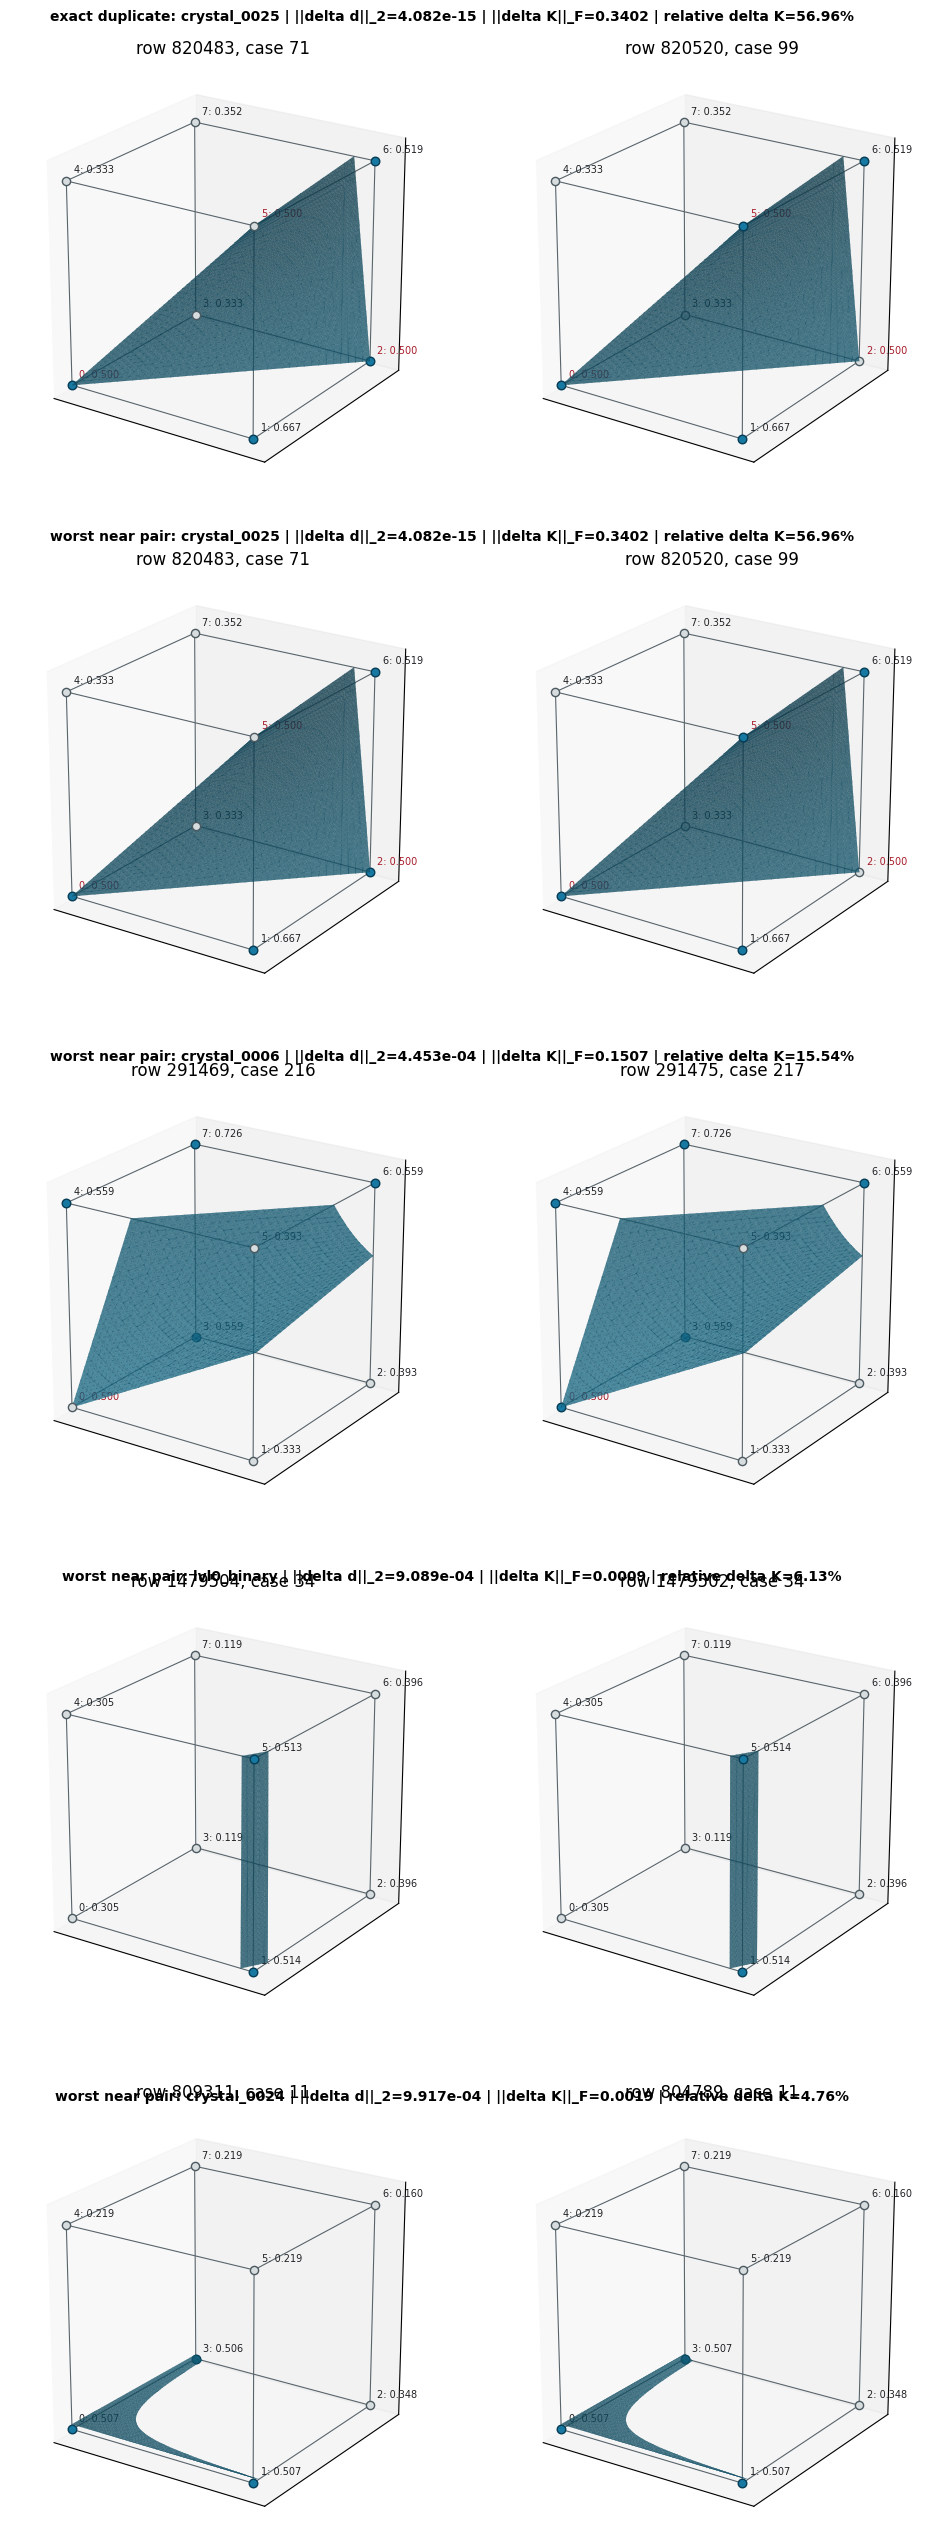

Blue corners have original normalized SDF d > 0.5. Red labels are numerically at the MC threshold d = 0.5.
The first row is the crystal_0025 exact-duplicate counterexample; the remaining rows maximize target disagreement with ||delta d||_2 <= 1e-3.


In [51]:
# Exact-lattice discontinuity gallery. Values are original normalized SDF samples:
# d = 0.5 + phi / (2 sqrt(3) h), with Marching Cubes at d = 0.5.
import base64
import os
import subprocess

from skimage.measure import marching_cubes

EXACT_DATA_PATH = "clean_simulation/outputs/data/exact_original_sdf_lattice_rebuilt_queso_i2_p1_all72.h5"
EXACT_ANALYSIS_DIR = ROOT / "clean_simulation" / "outputs" / "analysis" / "exact_original_sdf_lattice_health"
EXACT_ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
EXACT_REMOTE_OUTPUT = "clean_simulation/outputs/analysis/exact_original_sdf_lattice_health/discontinuity_gallery_pairs.csv"
EXACT_LOCAL_OUTPUT = EXACT_ANALYSIS_DIR / "discontinuity_gallery_pairs.csv"

remote_program = f'''\
import csv
import h5py
import numpy as np
from pathlib import Path
from scipy.spatial import cKDTree

with h5py.File({EXACT_DATA_PATH!r}, "r") as handle:
    group = handle["integration_2_poly_1"]
    names = group["geometry_name"][...].astype(str)
    upper_i, upper_j = np.triu_indices(24)
    weights = np.where(upper_i == upper_j, 1.0, 2.0)
    selected = [("exact duplicate", "crystal_0025", 820483, 820520)]
    candidates = []
    for name in np.unique(names):
        indices = np.flatnonzero(names == name)
        d = np.asarray(group["d_values"][indices], dtype=np.float64)
        k = np.asarray(group["stiffness_ut"][indices], dtype=np.float64)
        distance, neighbor = cKDTree(d).query(d, k=2)
        eligible = np.flatnonzero(distance[:, 1] <= 1e-3)
        if len(eligible):
            partner = neighbor[:, 1]
            delta = np.sqrt(np.sum(weights * (k - k[partner]) ** 2, axis=1))
            norm = np.sqrt(np.sum(weights * k * k, axis=1))
            relative = delta / np.maximum(0.5 * (norm + norm[partner]), 1e-12)
            local = eligible[np.argmax(relative[eligible])]
            candidates.append((relative[local], name, int(indices[local]), int(indices[partner[local]])))
    selected += [("worst near pair", name, first, second) for _, name, first, second in sorted(candidates, reverse=True)[:4]]
    rows = []
    for category, name, first, second in selected:
        da, db = np.asarray(group["d_values"][first]), np.asarray(group["d_values"][second])
        ka, kb = np.asarray(group["stiffness_ut"][first]), np.asarray(group["stiffness_ut"][second])
        na, nb = np.sqrt(np.sum(weights * ka * ka)), np.sqrt(np.sum(weights * kb * kb))
        dk = np.sqrt(np.sum(weights * (ka - kb) ** 2))
        rows.append({{
            "category": category, "geometry_name": name, "row_index": first, "neighbor_row_index": second,
            "sdf_l2_distance": float(np.linalg.norm(da - db)),
            "sdf_max_corner_difference": float(np.abs(da - db).max()),
            "K_difference_frobenius": float(dk), "relative_K_difference": float(dk / max(0.5 * (na + nb), 1e-12)),
            "case_code": int(np.sum((da > 0.5) * (1 << np.arange(8)))),
            "neighbor_case_code": int(np.sum((db > 0.5) * (1 << np.arange(8)))),
            **{{f"d{{corner}}_a": float(value) for corner, value in enumerate(da)}},
            **{{f"d{{corner}}_b": float(value) for corner, value in enumerate(db)}},
        }})
path = Path({EXACT_REMOTE_OUTPUT!r})
path.parent.mkdir(parents=True, exist_ok=True)
with path.open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)
print(f"wrote {{len(rows)}} pairs")
'''
encoded = base64.b64encode(remote_program.encode("utf-8")).decode("ascii")
completed = subprocess.run(
    ["ssh", "-o", "ConnectTimeout=15", "-i", str(SSH_KEY), REMOTE_HOST,
     f"cd ~/cutcell-training; echo {encoded} | base64 -d | ~/.venvs/cutcell/bin/python -"],
    capture_output=True, text=True,
)
if completed.returncode:
    raise RuntimeError(completed.stderr.strip())
print(completed.stdout.strip())

temporary = EXACT_LOCAL_OUTPUT.with_suffix(".csv.part")
completed = subprocess.run(
    ["scp", "-q", "-i", str(SSH_KEY), f"{REMOTE_HOST}:~/cutcell-training/{EXACT_REMOTE_OUTPUT}", str(temporary)],
    capture_output=True, text=True,
)
if completed.returncode:
    raise RuntimeError(completed.stderr.strip())
temporary.replace(EXACT_LOCAL_OUTPUT)
pairs = pd.read_csv(EXACT_LOCAL_OUTPUT)
display(pairs[["category", "geometry_name", "row_index", "neighbor_row_index", "sdf_l2_distance", "sdf_max_corner_difference", "K_difference_frobenius", "relative_K_difference", "case_code", "neighbor_case_code"]].style.format({
    "sdf_l2_distance": "{:.3e}", "sdf_max_corner_difference": "{:.3e}",
    "K_difference_frobenius": "{:.5f}", "relative_K_difference": "{:.2%}",
}))

corners = np.array([[0, 0, 0], [1, 0, 0], [1, 1, 0], [0, 1, 0], [0, 0, 1], [1, 0, 1], [1, 1, 1], [0, 1, 1]], dtype=float)
edges = ((0, 1), (1, 2), (2, 3), (3, 0), (4, 5), (5, 6), (6, 7), (7, 4), (0, 4), (1, 5), (2, 6), (3, 7))
coordinate = np.linspace(0.0, 1.0, 41)
x_grid, y_grid, z_grid = np.meshgrid(coordinate, coordinate, coordinate, indexing="ij")


def trilinear(values):
    weights = np.stack(((1-x_grid)*(1-y_grid)*(1-z_grid), x_grid*(1-y_grid)*(1-z_grid), x_grid*y_grid*(1-z_grid), (1-x_grid)*y_grid*(1-z_grid), (1-x_grid)*(1-y_grid)*z_grid, x_grid*(1-y_grid)*z_grid, x_grid*y_grid*z_grid, (1-x_grid)*y_grid*z_grid), axis=-1)
    return np.einsum("...c,c->...", weights, values)


def draw(axis, values, title):
    try:
        vertices, faces, _, _ = marching_cubes(trilinear(values), level=0.5, spacing=(1/40, 1/40, 1/40))
        axis.plot_trisurf(vertices[:, 0], vertices[:, 1], faces, vertices[:, 2], color="#2387a8", alpha=0.78, linewidth=0.1, edgecolor="#074760")
    except ValueError:
        pass
    for start, end in edges:
        axis.plot(*corners[[start, end]].T, color="#59646b", linewidth=0.8)
    inside = values > 0.5
    axis.scatter(*corners[~inside].T, color="#d7dcde", s=35, edgecolor="#4b5961", depthshade=False)
    axis.scatter(*corners[inside].T, color="#1778a1", s=38, edgecolor="#063d55", depthshade=False)
    for index, (point, value) in enumerate(zip(corners, values)):
        axis.text(*(point + [0.025, 0.025, 0.035]), f"{index}: {value:.3f}", fontsize=7, color="#a61b29" if abs(value-0.5) < 1e-8 else "#202124")
    axis.set(title=title, xlim=(-0.06, 1.10), ylim=(-0.06, 1.10), zlim=(-0.06, 1.10))
    axis.set_box_aspect((1, 1, 1))
    axis.set_xticks([]); axis.set_yticks([]); axis.set_zticks([])
    axis.view_init(elev=22, azim=-56)


figure = plt.figure(figsize=(12.5, 5.2 * len(pairs)))
for position, pair in pairs.reset_index(drop=True).iterrows():
    values_a = pair[[f"d{corner}_a" for corner in range(8)]].to_numpy(float)
    values_b = pair[[f"d{corner}_b" for corner in range(8)]].to_numpy(float)
    heading = f"{pair['category']}: {pair['geometry_name']} | ||delta d||_2={pair['sdf_l2_distance']:.3e} | ||delta K||_F={pair['K_difference_frobenius']:.4f} | relative delta K={pair['relative_K_difference']:.2%}"
    draw(figure.add_subplot(len(pairs), 2, 2*position+1, projection="3d"), values_a, f"row {int(pair['row_index'])}, case {int(pair['case_code'])}")
    draw(figure.add_subplot(len(pairs), 2, 2*position+2, projection="3d"), values_b, f"row {int(pair['neighbor_row_index'])}, case {int(pair['neighbor_case_code'])}")
    figure.text(0.5, 1.0-position/len(pairs)-0.01, heading, ha="center", va="top", fontsize=10, fontweight="bold")
figure.subplots_adjust(top=0.97, bottom=0.02, hspace=0.20, wspace=0.02)
plt.show()
print("Blue corners have original normalized SDF d > 0.5. Red labels are numerically at the MC threshold d = 0.5.")
print("The first row is the crystal_0025 exact-duplicate counterexample; the remaining rows maximize target disagreement with ||delta d||_2 <= 1e-3.")

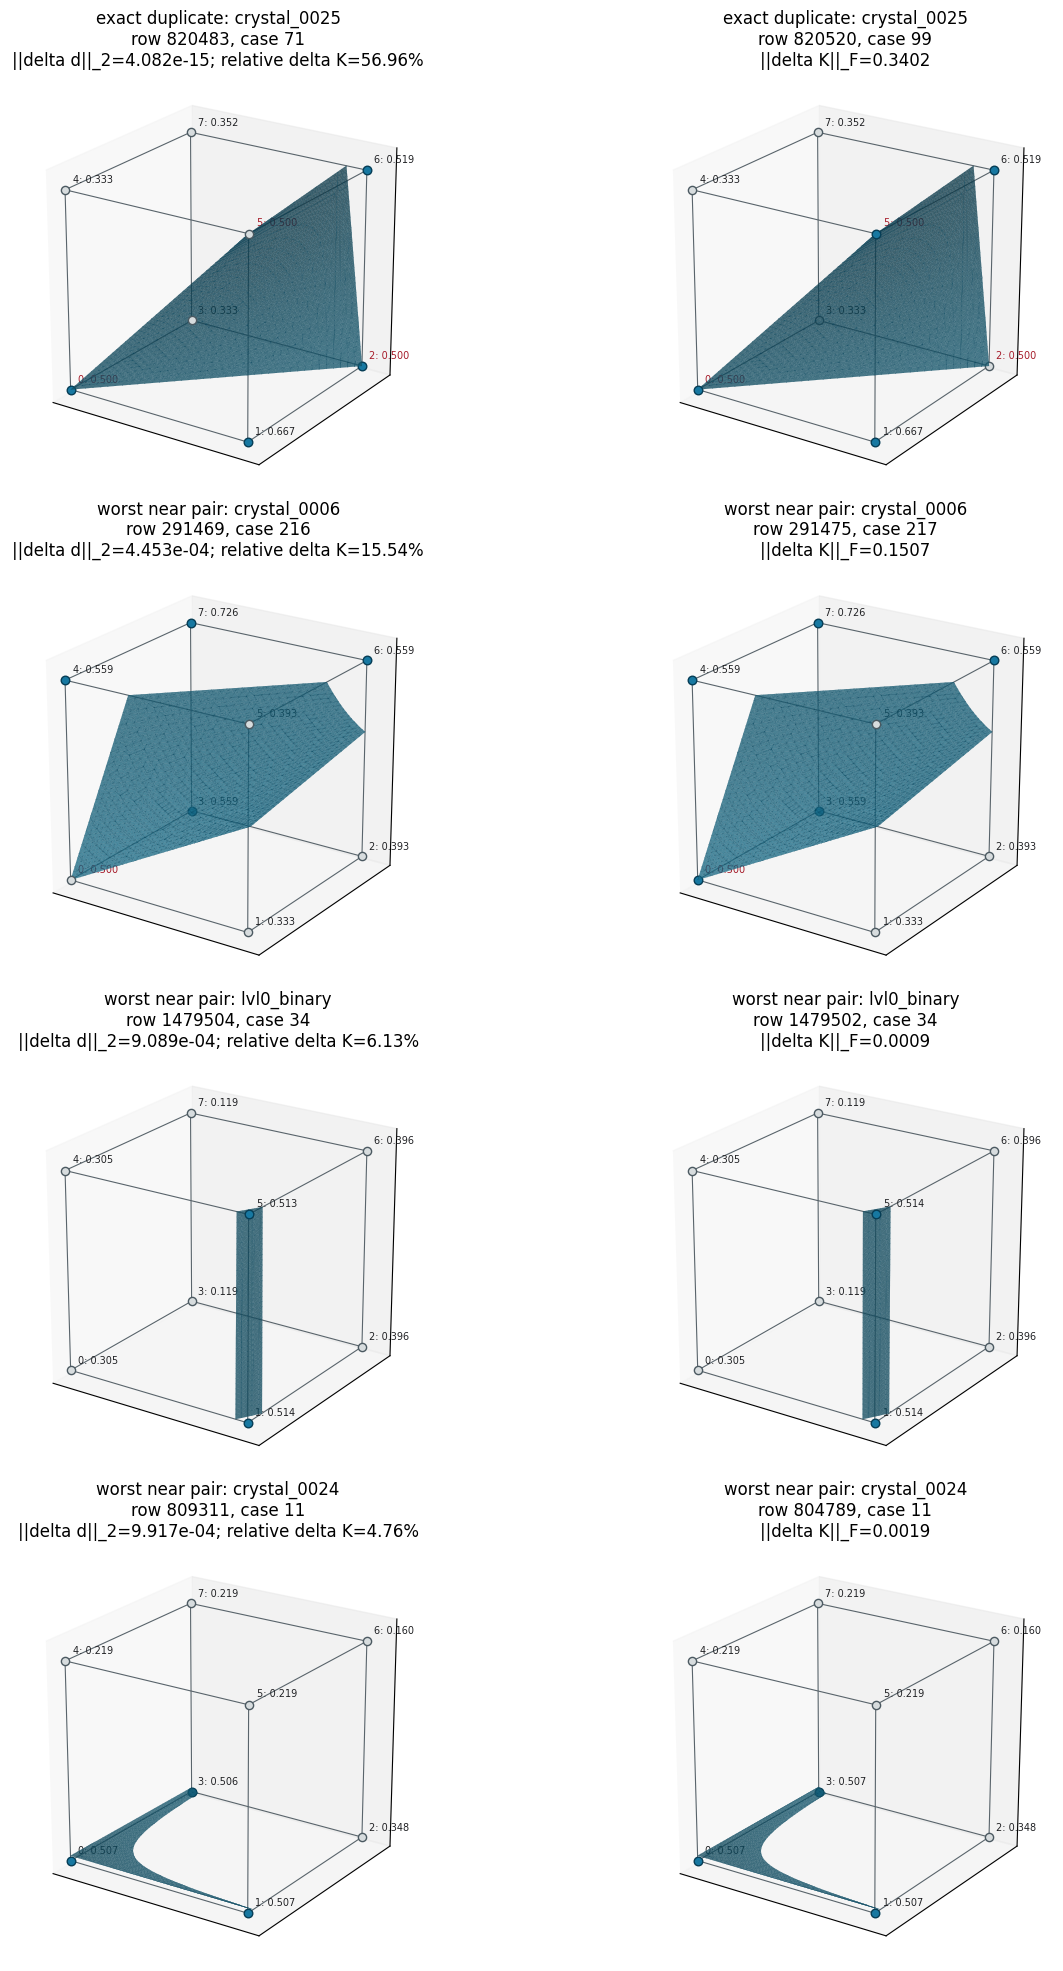

Rendered 4 unique discontinuity pairs from C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\analysis\exact_original_sdf_lattice_health\discontinuity_gallery_pairs.csv.


In [52]:
# Compact render of the synchronized exact-lattice pairs.
# This removes the forced-pair duplicate and uses per-panel titles to keep labels legible.
visible_pairs = pairs.drop_duplicates(["row_index", "neighbor_row_index"]).reset_index(drop=True)
figure = plt.figure(figsize=(12.5, 4.9 * len(visible_pairs)), constrained_layout=True)
for position, pair in visible_pairs.iterrows():
    values_a = pair[[f"d{corner}_a" for corner in range(8)]].to_numpy(float)
    values_b = pair[[f"d{corner}_b" for corner in range(8)]].to_numpy(float)
    metric = f"||delta d||_2={pair['sdf_l2_distance']:.3e}; relative delta K={pair['relative_K_difference']:.2%}"
    left = figure.add_subplot(len(visible_pairs), 2, 2 * position + 1, projection="3d")
    right = figure.add_subplot(len(visible_pairs), 2, 2 * position + 2, projection="3d")
    draw(left, values_a, f"{pair['category']}: {pair['geometry_name']}\nrow {int(pair['row_index'])}, case {int(pair['case_code'])}\n{metric}")
    draw(right, values_b, f"{pair['category']}: {pair['geometry_name']}\nrow {int(pair['neighbor_row_index'])}, case {int(pair['neighbor_case_code'])}\n||delta K||_F={pair['K_difference_frobenius']:.4f}")
plt.show()
print(f"Rendered {len(visible_pairs)} unique discontinuity pairs from {EXACT_LOCAL_OUTPUT}.")